<a href="https://colab.research.google.com/github/andrizomai/Pagoda-Business-Analytics-/blob/main/pagoda_capstone_analytics_(MSBA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pagoda (百果园, 2411.HK): Market Diagnostic and Turnaround Simulator

**MSBA Capstone, Analytics Workbook.** Existing-organisation pathway.

**Business question.** China's fresh-fruit retail market keeps growing in the Statista data, yet Pagoda's revenue fell 9.8% in 2024 and 20.4% in 2025 and the company moved from profit to loss. Is the problem the market or the company, and which operating lever matters most for getting back to profit?

**Notebook Overview**

| Step | Handbook section it supports | Output |
|---|---|---|
| 1 | Data Understanding | Inventory of every table in the Statista workbook and the company facts taken from the three analyst reports |
| 2 | Data Preparation | Tidy long-format dataset, automated validation checks, a data-quality log |
| 3 | Exploratory Data Analysis | Price/volume decomposition, segment mix, channel shift, Pagoda versus the market |
| 4 | Methods and Frameworks | Rolling-origin backtest of four forecasting methods, forecast with prediction interval, comparison with Statista's own forecast |
| 5 | Proof of Concept | Driver-based profit model calibrated to the analyst base case, Monte Carlo simulation, sensitivity and breakeven analysis |
| 6 | Evaluate Business Value | Value-at-stake figures the cost-benefit section can build on |

**How to run.** Choose *Run all*. In Colab the first code cell asks you to upload the Statista export (`Capstone China Fruits Statista.xlsx`); locally, put that file in the same folder first. The outputs saved below are from the author's run, so the results can be read without the file. Needs `pandas`, `numpy`, `scipy`, `matplotlib`, `openpyxl`. Everything is seeded, so results reproduce exactly.

**Sources**

Liu, Guangyi, and Xiaoying Peng. 2026. 百果园集团 (2411.HK): 水果连锁龙头，扬帆再次起航 (公司首次覆盖深度报告). China Galaxy Securities, April 10, 2026.

Statista Market Insights. 2026. “Fresh Fruits - China.” Accessed August 13, 2026. https://www.statista.com/outlook/cmo/food/fruits-nuts/fresh-fruits/china/?currency=USD.

Wong, Joseph. 2023. *Shenzhen Pagoda (2411 HK): Sowing the Franchiser's Seed*. CMB International Global Markets, March 3, 2023.

Xu, Zhuonan, and Jierui Wang. 2025. *Pagoda Industrial (Group): 2024 Losses Totaled Rmb386mn Due to Weak Consumer Spending and Product Strategy Adjustment*. China International Capital Corporation, April 4, 2025.

Xu, Zhuonan, Jierui Wang, and Yi Ding. 2026. *Pagoda Industrial (Group): Main Business Recovering in 1H26; Cooperation under Seven-Star Convention Alliance Advancing*. China International Capital Corporation, September 7, 2026.

In [ ]:
import warnings, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from openpyxl import load_workbook
from scipy import stats

# Locate the Statista export. It is licensed data and is not stored in the repository:
# in Colab you are asked to upload it; locally, put it next to this notebook.
def find_workbook():
    hits = sorted(p for p in Path(".").glob("*.xlsx") if "statista" in p.name.lower())
    if hits:
        return hits[0]
    try:
        from google.colab import files                    # only available in Colab
    except ImportError:
        raise FileNotFoundError("Put the Statista export (file name containing 'Statista', .xlsx) in this folder and re-run.")
    print("Upload the Statista Market Insights export: Fresh Fruits - China (.xlsx)")
    name = next(iter(files.upload()))
    return Path(name)

STATISTA_XLSX = find_workbook()
print("Using", STATISTA_XLSX)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
SEED = 20261006
HIST_END = 2025            # last year treated as history; later years are Statista's forecast
N_TRIALS = 20_000

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 160

# Chart style: validated categorical palette, thin marks, recessive grid
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
         green="#008300", violet="#4a3aa7", red="#e34948", ink="#0b0b0b", ink2="#52514e",
         muted="#898781", grid="#e1e0d9", good="#0ca30c", crit="#d03b3b")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": C["grid"], "grid.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": C["ink2"], "xtick.color": C["muted"], "ytick.color": C["muted"],
    "font.size": 9.5, "lines.linewidth": 2, "legend.frameon": False,
})
SEG_ORDER = ["Bananas", "Apples & Pears", "Other Fresh Fruits", "Citrus Fruits", "Berries & Grapes"]
SEG_COL = dict(zip(SEG_ORDER, [C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"]]))

Using Capstone China Fruits Statista.xlsx


## 1. Data Understanding

### 1.1 Statista workbook
Each Statista sheet stacks several tables on top of each other, separated by blank rows, each with its own title row, year header and footer (`Most recent update`, `Sources`, `Notes`). The loader below splits a sheet into those tables without hard-coding cell addresses, so a refreshed export with more years or rows still loads.

In [ ]:
FOOTER = ("Most recent update:", "Sources", "Notes")

def read_blocks(sheet):
    """Split one Statista sheet into its stacked tables.
    Returns {table title: DataFrame indexed by row label with integer year columns}."""
    ws = load_workbook(STATISTA_XLSX, data_only=True)[sheet]
    rows = [list(r) for r in ws.iter_rows(values_only=True)]
    blocks, i = {}, 0
    while i < len(rows) - 1:
        title, nxt = rows[i][0], rows[i + 1]
        is_header = nxt[0] in ("", None) and len(nxt) > 1 and str(nxt[1]).isdigit()
        if isinstance(title, str) and title.strip() and is_header:
            cols = [k for k, y in enumerate(nxt) if k > 0 and str(y).isdigit()]   # year columns only (skips e.g. a 'CAGR' column)
            years = [int(nxt[k]) for k in cols]
            j, labels, values = i + 2, [], []
            while j < len(rows) and rows[j][0] not in FOOTER + ("", None):
                labels.append(rows[j][0]); values.append([rows[j][k] for k in cols]); j += 1
            meta = {}
            while j < len(rows) and rows[j][0] in FOOTER:
                meta[rows[j][0].rstrip(":")] = rows[j][1]; j += 1
            df = pd.DataFrame(values, index=labels, columns=years).apply(pd.to_numeric, errors="coerce")  # blanks -> NaN
            df.attrs.update(meta)
            blocks[title.strip()] = df
            i = j
        else:
            i += 1
    return blocks

SHEETS = ["Revenue", "Volume", "Price", "Sales Channels", "Global Comparison", "Key Market Indicators"]
raw = {s: read_blocks(s) for s in SHEETS}

inventory = pd.DataFrame([
    dict(sheet=s, table=t, rows=len(df), first_year=df.columns.min(), last_year=df.columns.max(),
         updated=df.attrs.get("Most recent update"), missing_cells=int(df.isna().sum().sum()))
    for s, blocks in raw.items() for t, df in blocks.items()])
print(f"{len(inventory)} tables, {int(inventory.rows.sum())} series")
inventory

23 tables, 382 series


,sheet,table,rows,first_year,last_year,updated,missing_cells
0,Revenue,REVENUE in billion USD (US$),6,2018,2031,02/19/2026,0
1,Revenue,REVENUE CHANGE in percent,6,2019,2031,02/19/2026,0
2,Revenue,AVERAGE REVENUE PER CAPITA in USD (US$),6,2018,2031,02/19/2026,0
3,Volume,VOLUME in billion kilograms,6,2018,2031,02/19/2026,0
4,Volume,VOLUME CHANGE in percent,6,2019,2031,02/19/2026,0
5,Volume,AVERAGE VOLUME PER CAPITA in kilograms,6,2018,2031,02/19/2026,0
6,Price,PRICE PER UNIT in USD (US$),6,2018,2031,02/19/2026,0
7,Sales Channels,ONLINE REVENUE SHARE in percent,12,2018,2030,04/28/2026,0
8,Sales Channels,SHARE BY DEVICE in percent,18,2018,2030,04/28/2026,0
9,Global Comparison,REVENUE COMPARISON in billion USD (US$),151,2018,2031,02/19/2026,0


**Reading the inventory**

- The three market sheets (Revenue, Volume, Price) cover 2018 to 2031 for the total market and five segments. They were updated on 19 Feb 2026, so **2018 to 2025 is treated as history and 2026 to 2031 as Statista's forecast**. The 2025 value may still be a preliminary estimate since Statista does not mark it.
- Scope matters for interpretation: the market is retail sales of fresh fruit to private households for at-home consumption (B2C). Cut-fruit boxes, out-of-home consumption and processed fruit are excluded.
- `Key Market Indicators` was last updated on 01/09/2025 and behaves like an older projection, which is checked in section 2.

### 1.2 Company facts from the analyst reports
No Pagoda transaction data is available, so company figures are transcribed from the three analyst reports. Every value carries its source and page so it can be traced, and derived values are marked. Monetary values are RMB million.

In [ ]:
P = []  # (year, metric, value, unit, source, note)
def add(year, metric, value, unit, source, note=""):
    P.append(dict(year=year, metric=metric, value=value, unit=unit, source=source, note=note))

# Income statement
for y, v in [(2019, 8976), (2020, 8854), (2021, 10289)]:
    add(y, "revenue", v, "RMB mn", "CMB 2023 p.21")
add(2022, "revenue", round(11391 / 1.007), "RMB mn", "derived from CICC 2025 p.1", "derived: 2023 revenue / (1 + 0.7% growth)")
add(2023, "revenue", 11391, "RMB mn", "CICC 2025 p.1")
add(2024, "revenue", 10273, "RMB mn", "CICC 2025 p.1")
add(2025, "revenue", 8174, "RMB mn", "Galaxy 2026 p.1")
for y, v, s in [(2020, 49, "CMB 2023 p.35"), (2021, 235, "CMB 2023 p.35"), (2023, 362, "CICC 2025 p.1"), (2024, -386, "CICC 2025 p.1"), (2025, -317, "Galaxy 2026 p.1")]:
    add(y, "net_profit_attributable", v, "RMB mn", s)
for y, v, s in [(2019, 9.8, "Galaxy 2026 p.3"), (2020, 9.1, "CMB 2023 p.35"), (2021, 11.2, "CMB 2023 p.35"), (2023, 11.5, "CICC 2025 p.3"), (2024, 7.4, "CICC 2025 p.3"), (2025, 7.3, "Galaxy 2026 p.18")]:
    add(y, "gross_margin", v, "%", s)
for y, v, s in [(2019, 3.8, "Galaxy 2026 p.3"), (2023, 4.2, "CICC 2025 p.4"), (2024, 5.9, "CICC 2025 p.2"), (2025, 6.5, "Galaxy 2026 p.18")]:
    add(y, "selling_expense_ratio", v, "%", s)
for y, v, s in [(2024, 4.5, "Galaxy 2026 p.18"), (2025, 3.8, "Galaxy 2026 p.18")]:
    add(y, "admin_rd_expense_ratio", v, "%", s)
# Half-year gross margin
for h, v, s in [("1H23", 11.3, "CICC 2025 p.4"), ("2H23", 11.8, "CICC 2025 p.4"), ("1H24", 11.1, "CICC 2025 p.4"),
                ("2H24", 3.1, "CICC 2025 p.4"), ("2H25", 10.0, "Galaxy 2026 p.10")]:
    add(h, "gross_margin_half", v, "%", s, "2H25 quoted as 'back to 10%'" if h == "2H25" else "")
# Store network
for y, v, s, n in [(2022, 5650, "Galaxy 2026 p.5", ""), (2023, 6093, "Galaxy 2026 p.5", ""),
                   (2024, 5127, "CICC 2025 p.1", "4,039 franchised + 1,077 regional-agent + 11 self-operated"),
                   (2025, 4468, "Galaxy 2026 p.10, p.17", "4,460 franchise network + 8 self-operated")]:
    add(y, "stores_total_year_end", v, "stores", s, n)
for y, v in [(2024, 5116), (2025, 4460)]:
    add(y, "stores_franchise_network_year_end", v, "stores", "Galaxy 2026 p.17", "franchised + regional-agent stores")
add("1H25", "stores_franchise_network_period_end", 4375, "stores", "Galaxy 2026 p.10")
for y, v in [(2024, 1.48), (2025, 1.48)]:
    add(y, "revenue_per_network_store", v, "RMB mn", "Galaxy 2026 p.17")
# Revenue by channel (Galaxy 2026, table 1)
channels = {"franchise_stores": (7396, 5912), "regional_agents": (1215, 855), "self_operated": (41, 21),
            "direct_sales": (1256, 1191), "online": (106, 61), "other": (259, 134)}
for ch, (v24, v25) in channels.items():
    add(2024, f"revenue_{ch}", v24, "RMB mn", "Galaxy 2026 p.17"); add(2025, f"revenue_{ch}", v25, "RMB mn", "Galaxy 2026 p.17")
# Customers and footprint
add(2024, "members", 90.74, "mn", "CICC 2025 p.1"); add(2024, "paid_members", 0.854, "mn", "CICC 2025 p.1", "-27.0% YoY")
add(2024, "online_share_of_orders", 25.2, "%", "CICC 2025 p.1", "share of orders, not of revenue")
for tier, v in [("tier1", 26), ("tier2", 36), ("tier3_and_below", 39)]:
    add(2025, f"store_share_{tier}", v, "%", "Galaxy 2026 p.5", "chart values; sum to 101 through rounding")
for city, v in [("Shenzhen", 22), ("Shanghai", 11), ("Guangzhou", 10), ("Beijing", 3)]:
    add(2025, f"stores_per_mn_people_{city}", v, "stores/mn", "Galaxy 2026 p.9")

pagoda = pd.DataFrame(P)
pagoda.to_csv(OUT / "pagoda_facts.csv", index=False)

# Internal consistency: the channel lines must add up to reported revenue
for y in (2024, 2025):
    ch_sum = pagoda[(pagoda.year == y) & pagoda.metric.str.startswith("revenue_") & (pagoda.unit == "RMB mn")
                    & (pagoda.metric != "revenue_per_network_store")].value.sum()
    total = pagoda[(pagoda.year == y) & (pagoda.metric == "revenue")].value.iloc[0]
    assert ch_sum == total, (y, ch_sum, total)
    print(f"{y}: channel lines sum to {ch_sum:,.0f} = reported revenue {total:,.0f}")
print(f"{len(pagoda)} company facts recorded")

# Analyst forecasts, used to calibrate and benchmark the simulator in section 5
GALAXY = pd.DataFrame({
    "revenue": [8746, 9744, 10927], "net_profit": [15, 169, 253],
    "franchise_stores": [6062, 6654, 7412], "regional_agents": [855, 897, 987], "direct_sales": [1549, 1859, 2138],
    "self_operated": [18, 19, 19], "online": [61, 64, 70], "other": [201, 251, 302],
    "stores_end": [4728, 5106, 5616], "rev_per_store": [1.51, 1.54, 1.57],
    "gross_margin": [0.102, 0.110, 0.115], "selling": [0.060, 0.055, 0.054], "admin_rd": [0.035, 0.032, 0.031],
}, index=pd.Index([2026, 2027, 2028], name="year"))          # Galaxy 2026 pp.17-18
CICC = pd.DataFrame({"revenue": [9176, 9939], "net_profit": [-297, 119], "gross_margin": [0.078, 0.106]},
                    index=pd.Index([2025, 2026], name="year"))  # CICC 2025 p.3
CICC_PREVIOUS_2025E = dict(revenue=10765, net_profit=220)       # CICC 2025 p.4, forecast before the April 2025 cut
CICC_SEP26 = pd.DataFrame({"revenue": [10286, 12024], "net_profit": [119, 184], "gross_margin": [0.107, 0.109], "cogs": [9186, 10717]},
                          index=pd.Index([2026, 2027], name="year"))  # CICC 2026 pp.1, 3 (made after 1H26 results; includes the Seven-Star alliance)
CMB = pd.DataFrame({"revenue": [12752, 14308], "net_profit": [447, 586], "gross_margin": [0.124, 0.129], "stores_end": [6470, 7030]},
                   index=pd.Index([2023, 2024], name="year"))  # CMB 2023 pp.1, 20, 35 (initiation forecast, March 2023)
# Business-model facts from CMB 2023 used in the interpretation
add(2021, "royalty_and_franchise_income_share_of_revenue", round(160.288 / 10289.375 * 100, 1), "%", "CMB 2023 p.21", "franchisees pay a monthly royalty set as a share of store gross profit (p.13)")
add(2021, "market_share_frost_sullivan", 1.0, "%", "CMB 2023 p.5", "share of China fruit retail sales value; top five retailers hold 3.6%")
add(2021, "inventory_days", 9.9, "days", "CMB 2023 p.35")
for g, lo_, hi_ in [("excellent", 19.9, 24.6), ("grade_a", 13.3, 14.9)]:
    add("2019-21", f"asp_rmb_per_kg_{g}_low", lo_, "RMB/kg", "CMB 2023 p.9"); add("2019-21", f"asp_rmb_per_kg_{g}_high", hi_, "RMB/kg", "CMB 2023 p.9")
# CMB 2023: cost structure
add(2021, "fruit_cost_share_of_cogs", 95.3, "%", "CMB 2023 p.29")

# CICC 2026 (results review of 1H26, published 7 Sep 2026)
for h, rev, gp, npf, adj, gm, opm in [("1H25", 4376, 216, -342, -295, 4.9, -7.2), ("2H25", 3799, 382, 25, 29, 10.0, 1.5), ("1H26", 5008, 609, 34, 61, 12.2, 1.3)]:
    add(h, "revenue_half", rev, "RMB mn", "CICC 2026 p.4"); add(h, "gross_profit_half", gp, "RMB mn", "CICC 2026 p.4")
    add(h, "net_profit_half", npf, "RMB mn", "CICC 2026 p.4"); add(h, "adjusted_net_profit_half", adj, "RMB mn", "CICC 2026 p.4")
    add(h, "gross_margin_half_cicc", gm, "%", "CICC 2026 p.4"); add(h, "operating_margin_half", opm, "%", "CICC 2026 p.4")
add("1H26", "revenue_growth_yoy", 14.5, "%", "CICC 2026 p.1")
add("1H26", "franchise_store_revenue", 3080, "RMB mn", "CICC 2026 p.1", "+0.1% YoY")
add("1H26", "daily_sales_per_store_growth_yoy", 1.4, "%", "CICC 2026 p.1", "store-level sales measure, not Pagoda revenue per store")
add("1H26", "franchise_store_gross_profit_growth_yoy", 3.0, "%", "CICC 2026 p.1", "'approximately 3%'")
add("1H26", "stores_franchise_network_period_end", 4752, "stores", "CICC 2026 p.1", "+377 YoY")
add("1H26", "share_of_new_stores_tier3_and_below", 45, "%", "CICC 2026 p.1")
add("1H26", "online_share_of_orders", 27.8, "%", "CICC 2026 p.1", "+3.1 pt YoY")
add("1H26", "members", 97.7, "mn", "CICC 2026 p.1", "+5% YoY")
add("1H26", "seven_star_alliance_revenue", 721, "RMB mn", "CICC 2026 p.1", "seven regional retail brands in seven provinces; 'fruit + snack' format")
add("1H26", "seven_star_alliance_gross_margin_est", 7.7, "%", "CICC 2026 p.1", "CICC estimate")
add("1H26", "gross_margin_excluding_alliance", 12.9, "%", "CICC 2026 p.1", "CICC 'comparable basis'; attributed to optimisation of the fruit product mix")
for k, v in [("selling", 5.7), ("g_and_a", 4.5), ("r_and_d", 0.8)]:
    add("1H26", f"{k}_expense_ratio", v, "%", "CICC 2026 p.1")
for k, v in [("cogs", 7577), ("selling_expenses", 535), ("administrative_expenses", 203)]:
    add(2025, k, v, "RMB mn", "CICC 2026 p.3")

pagoda = pd.DataFrame(P)                       # rebuilt so the facts added above are included
pagoda.to_csv(OUT / "pagoda_facts.csv", index=False)
print(f"{len(pagoda)} company facts recorded")
line_gap = GALAXY[["franchise_stores", "regional_agents", "direct_sales", "self_operated", "online", "other"]].sum(axis=1) - GALAXY.revenue
assert line_gap.abs().max() <= 2          # Galaxy's lines add to its total within rounding
print("Galaxy forecast: channel lines minus total, RMB mn:", line_gap.tolist())
pagoda[pagoda.metric.isin(["revenue", "net_profit_attributable", "gross_margin"])].pivot(index="year", columns="metric", values="value")

2024: channel lines sum to 10,273 = reported revenue 10,273
2025: channel lines sum to 8,174 = reported revenue 8,174
60 company facts recorded
103 company facts recorded
Galaxy forecast: channel lines minus total, RMB mn: [0, 0, 1]


metric,gross_margin,net_profit_attributable,revenue
year,,,
2019,9.80,NaN,"8,976.00"
2020,9.10,49.00,"8,854.00"
2021,11.20,235.00,"10,289.00"
2022,NaN,NaN,"11,312.00"
2023,11.50,362.00,"11,391.00"
2024,7.40,-386.00,"10,273.00"
2025,7.30,-317.00,"8,174.00"


## 2. Data Preparation

### 2.1 Tidy Dataset
The five market tables are reshaped to one long table (`segment`, `year`, `metric`, `value`) and one wide analysis table. `Average` in the price table is renamed `Total` so it lines up with the other tables.

In [ ]:
def to_long(df, metric):
    out = df.rename_axis("segment").reset_index().melt(id_vars="segment", var_name="year", value_name="value")
    out["metric"] = metric
    return out

market_long = pd.concat([
    to_long(raw["Revenue"]["REVENUE in billion USD (US$)"], "revenue_usd_bn"),
    to_long(raw["Volume"]["VOLUME in billion kilograms"], "volume_bn_kg"),
    to_long(raw["Price"]["PRICE PER UNIT in USD (US$)"].rename(index={"Average": "Total"}), "price_usd_per_kg"),
    to_long(raw["Revenue"]["AVERAGE REVENUE PER CAPITA in USD (US$)"], "revenue_per_capita_usd"),
    to_long(raw["Volume"]["AVERAGE VOLUME PER CAPITA in kilograms"], "volume_per_capita_kg"),
], ignore_index=True)
market_long["year"] = market_long.year.astype(int)
market_long["status"] = np.where(market_long.year <= HIST_END, "history", "statista_forecast")
market_long = market_long[["segment", "year", "status", "metric", "value"]].sort_values(["metric", "segment", "year"])
market_long.to_csv(OUT / "market_tidy_long.csv", index=False)

mk = market_long.pivot(index=["segment", "year"], columns="metric", values="value").sort_index()
YEARS = sorted(market_long.year.unique()); HIST = [y for y in YEARS if y <= HIST_END]; FCST = [y for y in YEARS if y > HIST_END]
SEGS = [s for s in SEG_ORDER if s in mk.index.get_level_values(0)]
assert len(SEGS) == 5 and "Total" in mk.index.get_level_values(0)
print(f"{len(market_long):,} rows; {market_long.segment.nunique()} series x {len(YEARS)} years x {market_long.metric.nunique()} metrics; "
      f"missing values: {int(market_long.value.isna().sum())}")
mk.loc["Total"].T.round(2)

420 rows; 6 series x 14 years x 5 metrics; missing values: 0


year,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030,2031
metric,,,,,,,,,,,,,,
price_usd_per_kg,2.15,2.20,2.34,2.43,2.47,2.52,2.56,2.61,2.66,2.71,2.77,2.84,3.00,3.15
revenue_per_capita_usd,39.72,42.46,48.31,53.83,58.60,63.70,70.13,76.69,84.10,89.63,96.34,103.34,114.86,125.83
revenue_usd_bn,56.66,60.75,69.26,77.19,83.96,91.10,100.06,109.17,119.45,127.02,136.19,145.68,161.46,176.32
volume_bn_kg,26.35,27.59,29.65,31.74,33.94,36.16,39.02,41.79,44.90,46.91,49.18,51.28,53.81,55.89
volume_per_capita_kg,18.48,19.28,20.68,22.14,23.69,25.28,27.35,29.36,31.61,33.10,34.79,36.38,38.28,39.89


### 2.2 Validation Checks
Statista's figures are modelled estimates, so they cannot be audited against a ledger. What can be tested is whether the tables agree with each other. Each check below is an accounting identity or a comparison with a value Statista reports elsewhere in the same workbook, followed by an outlier scan. Tolerances allow for the two-decimal rounding in the export.

In [ ]:
dq = []   # data-quality log
def log(check, result, detail, action):
    dq.append(dict(check=check, result=result, detail=detail, action=action))

rev_w = mk.revenue_usd_bn.unstack("year"); vol_w = mk.volume_bn_kg.unstack("year"); prc_w = mk.price_usd_per_kg.unstack("year")

# 1-2  segments add up to the total
for name, w, tol in [("Revenue: segments sum to total", rev_w, 0.03), ("Volume: segments sum to total", vol_w, 0.03)]:
    gap = (w.loc[SEGS].sum() - w.loc["Total"]).abs().max()
    log(name, "pass" if gap <= tol else "FLAG", f"largest gap {gap:.3f} bn", "none")

# 3  revenue / volume reproduces the published price per kg
implied = rev_w / vol_w
rel = ((implied - prc_w) / prc_w).abs()
log("Price: revenue / volume equals price per kg", "pass" if rel.max().max() < 0.01 else "FLAG",
    f"largest relative gap {rel.max().max():.2%} ({rel.max(axis=1).idxmax()})", "none")

# 4  one population is used throughout (revenue / revenue per capita)
pop = (mk.revenue_usd_bn / mk.revenue_per_capita_usd).unstack("year")            # billions of people
pop_spread = ((pop.max() - pop.min()) / pop.loc["Total"]).max()
pop_vol = (mk.volume_bn_kg / mk.volume_per_capita_kg).unstack("year").loc["Total"]
log("Per capita: one implied population across tables", "pass" if pop_spread < 0.01 else "FLAG",
    f"spread across segments up to {pop_spread:.2%}; implied population {pop.loc['Total', 2018]:.3f}bn (2018), "
    f"{pop.loc['Total', HIST_END]:.3f}bn ({HIST_END}); volume table agrees within {((pop_vol - pop.loc['Total']).abs() / pop.loc['Total']).max():.2%}",
    "implied population reused as the population driver in section 4")

# 5  published growth rates are consistent with the published levels, given two-decimal rounding of the levels
for name, key, sheet in [("Revenue", "REVENUE CHANGE in percent", "Revenue"), ("Volume", "VOLUME CHANGE in percent", "Volume")]:
    w = rev_w if name == "Revenue" else vol_w
    published = raw[sheet][key].dropna(axis=1, how="all")
    prev, cur = w.shift(axis=1).loc[published.index, published.columns], w.loc[published.index, published.columns]
    lo = ((cur - 0.005) / (prev + 0.005) - 1) * 100 - 0.05          # lowest growth the rounded levels allow
    hi = ((cur + 0.005) / (prev - 0.005) - 1) * 100 + 0.05          # highest
    outside = ((published < lo) | (published > hi)).sum().sum()
    raw_gap = ((cur / prev - 1) * 100 - published).abs()
    worst = raw_gap.stack().idxmax()
    log(f"{name}: published growth consistent with published levels", "pass" if outside == 0 else "FLAG",
        f"{outside} of {published.size} growth rates fall outside the range rounding allows; largest raw gap {raw_gap.max().max():.2f} pt ({worst[0]}, {worst[1]})",
        "none")

# 6  sales channels: every Online row has an Offline partner summing to 100
ch = raw["Sales Channels"]["ONLINE REVENUE SHARE in percent"]
online = ch[ch.index == "Online"].reset_index(drop=True); offline = ch[ch.index == "Offline"].reset_index(drop=True)
pairs = [(i, j) for i in online.index for j in offline.index if ((online.loc[i] + offline.loc[j] - 100).abs() < 0.25).all()]
log("Sales channels: online + offline = 100", "pass" if len(pairs) == len(online) else "FLAG",
    f"{len(pairs)} of {len(online)} online series have a matching offline series", "none")

# 7  outlier scan on year-over-year changes (robust z-score per series)
flags = []
for metric in ["revenue_usd_bn", "volume_bn_kg", "price_usd_per_kg"]:
    g = mk[metric].unstack("year").pct_change(axis=1).dropna(axis=1, how="all") * 100
    med = g.median(axis=1); mad = (g.sub(med, axis=0)).abs().median(axis=1) * 1.4826
    z = g.sub(med, axis=0).div(mad, axis=0)
    for (seg, yr), zval in z.stack().items():
        if abs(zval) > 6:
            flags.append(dict(metric=metric, segment=seg, year=yr, yoy_pct=round(g.loc[seg, yr], 1), robust_z=round(zval, 1)))
outliers = pd.DataFrame(flags).sort_values(["segment", "metric", "year"]).reset_index(drop=True)
outliers

,metric,segment,year,yoy_pct,robust_z
0,price_usd_per_kg,Berries & Grapes,2020,35.50,73.00
1,price_usd_per_kg,Berries & Grapes,2021,25.50,51.20
2,price_usd_per_kg,Berries & Grapes,2030,5.80,8.10
3,price_usd_per_kg,Berries & Grapes,2031,5.40,7.20
4,price_usd_per_kg,Citrus Fruits,2020,4.90,6.10
5,price_usd_per_kg,Citrus Fruits,2021,-1.00,-6.30
6,price_usd_per_kg,Citrus Fruits,2030,5.90,8.00
7,price_usd_per_kg,Citrus Fruits,2031,5.50,7.40
8,price_usd_per_kg,Other Fresh Fruits,2030,5.80,9.30
9,price_usd_per_kg,Other Fresh Fruits,2031,5.50,8.50


The scan returns three significant patterns:

1. **Berries & Grapes, 2020 to 2021.** Volume falls 16% and 11% while the price per kg jumps from 4.45 to 7.57 USD. Revenue keeps growing smoothly at the same rate as every other segment, so the break is in how value is split between price and volume, not in the value itself. This looks like a re-basing of the series rather than a market event. Consequence: price and volume trends for this segment are not used on their own; the segment is analysed on revenue only.
2. **Statista's forecast in 2030 and 2031.** Average price steps up 5.6% and 5.0% after a decade of 1 to 3% a year, across all segments at once. No reason is given in the export. Consequence: Statista's 2030 to 2031 values are treated as the less reliable end of its forecast in section 4.
3. **2020, total and Citrus.** The total price rises 6.4% in 2020. Part of that is the Berries & Grapes break feeding into the total; the Citrus wobble (+4.9% then -1.0%) is small. Neither changes a conclusion, and section 3.1 repeats the price/volume split without Berries & Grapes to confirm it.

In [ ]:
for seg, metric, yrs, action in [
    ("Berries & Grapes", "price_usd_per_kg", (2020, 2021), "segment analysed on revenue only; excluded from price and volume trend fitting"),
    ("Total", "price_usd_per_kg", (2030, 2031), "Statista forecast for 2030-31 treated as lower confidence")]:
    sub = outliers[(outliers.segment == seg) & (outliers.metric == metric) & outliers.year.isin(yrs)]
    yoy = (prc_w.pct_change(axis=1) * 100).loc[seg, list(yrs)].round(1).tolist()
    log(f"Outlier scan: {seg} price, {yrs[0]}-{yrs[1]}", "FLAG", f"price change {yoy[0]:+.1f}% and {yoy[1]:+.1f}% against a series median of "
        f"{(prc_w.pct_change(axis=1) * 100).loc[seg].median():+.1f}%", action)

### 2.3 What falls short?

**Sales-channel rows have lost their labels.** The export contains six `Online` and six `Offline` rows with no segment names. The cell below tests whether the labels can be recovered: if one row is the market total, it must equal the revenue-weighted average of five others. All 720 possible assignments are tried.

In [ ]:
import itertools
rev_h = rev_w[[c for c in online.columns if c in rev_w.columns]]
fits = []
for total_row in online.index:
    others = [i for i in online.index if i != total_row]
    for perm in itertools.permutations(others):
        weighted = sum(rev_h.loc[s] * online.loc[p, rev_h.columns] for s, p in zip(SEGS, perm)) / rev_h.loc["Total"]
        fits.append((float((weighted - online.loc[total_row, rev_h.columns]).abs().mean()), total_row, perm))
fits.sort(key=lambda f: f[0])
best, runner_up = fits[0], fits[1]
print(f"best assignment: mean absolute error {best[0]:.2f} pt (row {best[1]} as total); runner-up {runner_up[0]:.2f} pt")
print("rounding alone would allow about 0.05 pt, so no assignment reproduces the total")

online_T = online.T; online_T.columns = [f"series {i + 1}" for i in online_T.columns]
channel_summary = pd.DataFrame({"lowest series": online_T.min(axis=1), "median of six": online_T.median(axis=1), "highest series": online_T.max(axis=1)})
jump = online_T.diff().abs().stack().idxmax()
log("Sales channels: row labels", "FLAG", f"6 unlabelled online series; best label assignment misses by {best[0]:.2f} pt on average, so labels cannot be recovered",
    "report only the label-free pattern (range and median); re-export from Statista with labels")
log("Sales channels: series continuity", "FLAG", f"{jump[1]} jumps {online_T.diff().loc[jump[0], jump[1]]:+.1f} pt in {jump[0]}",
    "series not used individually")
channel_summary.loc[[2018, 2021, 2023, 2025, 2030]].round(1)

best assignment: mean absolute error 0.51 pt (row 4 as total); runner-up 0.56 pt
rounding alone would allow about 0.05 pt, so no assignment reproduces the total


,lowest series,median of six,highest series
2018,4.10,9.10,14.50
2021,10.20,22.90,36.40
2023,9.70,18.40,30.20
2025,10.40,22.20,38.50
2030,16.10,27.00,52.00


The labels cannot be recovered, so the analysis uses only what holds for **all six series**: the online share more than doubled between 2018 and 2021, fell back in 2022 and 2023, and is rising again. The fix is a fresh Statista export with labels.

**The macro sheet is a stale projection.** The `Key Market Indicators` sheet gives CNY/USD rates for 2021 to 2025, but the values slide smoothly downward, the telltale pattern of a projection rather than observed rates. The sheet's own `Domestic Credit` series is also off by a factor of 100. The cell below shows the evidence. So the macro sheet is used for just one thing, the currency conversion in section 3.4, and that conversion is stress-tested.

In [ ]:
kmi = raw["Key Market Indicators"]
fx = kmi["EXCHANGE RATES"].loc["CNY (CN¥)"]
credit = kmi["BUSINESS CYCLE"].loc["Domestic Credit (% of GDP) in percent"]
fx_steps = fx.loc[2021:2030].diff().dropna()
log("Key Market Indicators: values after 2020 are projections", "FLAG",
    f"CNY per USD falls every year from {fx[2021]:.2f} (2021) to {fx[2030]:.2f} (2030) in steps of {fx_steps.min():.3f} to {fx_steps.max():.3f}; "
    f"Domestic Credit reads {credit[2024]:,.0f}% of GDP", "sheet used only for the FX conversion in 3.4, with a sensitivity range")
fx.loc[2018:2026].round(4).to_frame("CNY per USD in workbook").T

,2018,2019,2020,2021,2022,2023,2024,2025,2026
CNY per USD in workbook,6.62,6.91,6.90,6.83,6.81,6.78,6.76,6.73,6.71


In [ ]:
dq_log = pd.DataFrame(dq)
dq_log.to_csv(OUT / "data_quality_log.csv", index=False)
print(f"{(dq_log.result == 'pass').sum()} checks passed, {(dq_log.result == 'FLAG').sum()} items flagged")
with pd.option_context("display.max_colwidth", 200):
    display(dq_log)

7 checks passed, 5 items flagged


,check,result,detail,action
0,Revenue: segments sum to total,pass,largest gap 0.010 bn,none
1,Volume: segments sum to total,pass,largest gap 0.020 bn,none
2,Price: revenue / volume equals price per kg,pass,largest relative gap 0.34% (Citrus Fruits),none
3,Per capita: one implied population across tables,pass,"spread across segments up to 0.09%; implied population 1.426bn (2018), 1.424bn (2025); volume table agrees within 0.01%",implied population reused as the population driver in section 4
4,Revenue: published growth consistent with published levels,pass,"0 of 78 growth rates fall outside the range rounding allows; largest raw gap 0.11 pt (Berries & Grapes, 2021)",none
5,Volume: published growth consistent with published levels,pass,"0 of 78 growth rates fall outside the range rounding allows; largest raw gap 0.64 pt (Berries & Grapes, 2022)",none
6,Sales channels: online + offline = 100,pass,6 of 6 online series have a matching offline series,none
7,"Outlier scan: Berries & Grapes price, 2020-2021",FLAG,price change +35.5% and +25.5% against a series median of +2.1%,segment analysed on revenue only; excluded from price and volume trend fitting
8,"Outlier scan: Total price, 2030-2031",FLAG,price change +5.6% and +5.0% against a series median of +2.2%,Statista forecast for 2030-31 treated as lower confidence
9,Sales channels: row labels,FLAG,"6 unlabelled online series; best label assignment misses by 0.51 pt on average, so labels cannot be recovered",report only the label-free pattern (range and median); re-export from Statista with labels


## 3. Exploratory Data Analysis

### 3.1 Where does market growth come from?
Revenue is volume times price, so growth in log terms splits exactly into a volume part and a price part. Volume splits again into population and consumption per person.

Average annual log growth, percentage points


,revenue,price,volume,population,volume_per_capita,volume_share_of_growth_pct
History 2018-2025,9.37,2.77,6.59,-0.03,6.62,70.32
Statista forecast 2025-2031,7.99,3.13,4.85,-0.26,5.11,60.64


Volume share of 2018-2025 growth: 70% for the total, 73% excluding Berries & Grapes
Revenue CAGR 2018-2025: 9.8%; Statista 2025-2031: 8.3%
Consumption per person: 18.5 kg (2018) -> 29.4 kg (2025)


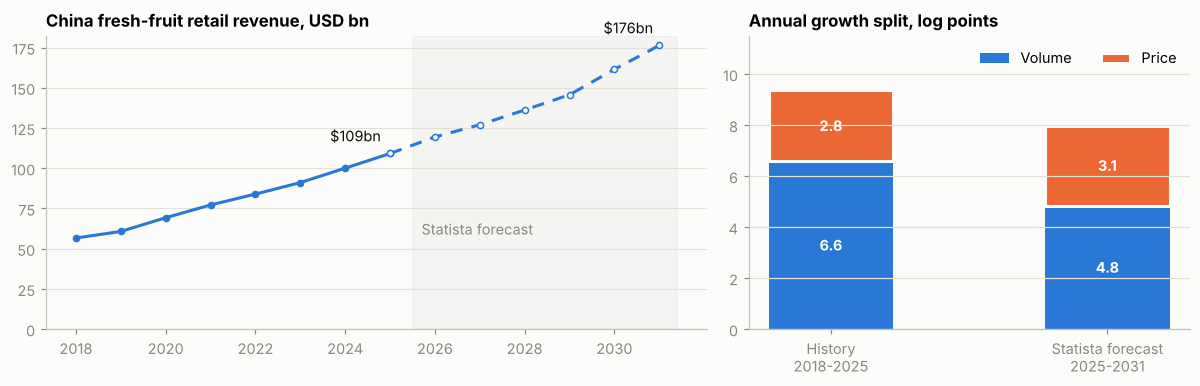

In [ ]:
def cagr(series, y0, y1):
    return (series[y1] / series[y0]) ** (1 / (y1 - y0)) - 1

tot = mk.loc["Total"]; popn = pop.loc["Total"]
def decompose(y0, y1):
    n = y1 - y0
    parts = dict(revenue=np.log(tot.revenue_usd_bn[y1] / tot.revenue_usd_bn[y0]) / n,
                 price=np.log(tot.price_usd_per_kg[y1] / tot.price_usd_per_kg[y0]) / n,
                 volume=np.log(tot.volume_bn_kg[y1] / tot.volume_bn_kg[y0]) / n,
                 population=np.log(popn[y1] / popn[y0]) / n,
                 volume_per_capita=np.log(tot.volume_per_capita_kg[y1] / tot.volume_per_capita_kg[y0]) / n)
    return {k: v * 100 for k, v in parts.items()}

decomp = pd.DataFrame({f"History 2018-{HIST_END}": decompose(2018, HIST_END),
                       f"Statista forecast {HIST_END}-2031": decompose(HIST_END, 2031)}).T
decomp["volume_share_of_growth_pct"] = decomp.volume / decomp.revenue * 100
print("Average annual log growth, percentage points")
display(decomp.round(2))

# Robustness: the Berries & Grapes series break (section 2.2) sits inside the total. Repeat the split without that segment.
ex = [s_ for s_ in SEGS if s_ != "Berries & Grapes"]
ex_rev, ex_vol = rev_w.loc[ex].sum(), vol_w.loc[ex].sum()
ex_volume_share = np.log(ex_vol[HIST_END] / ex_vol[2018]) / np.log(ex_rev[HIST_END] / ex_rev[2018]) * 100
print(f"Volume share of 2018-{HIST_END} growth: {decomp.volume_share_of_growth_pct.iloc[0]:.0f}% for the total, {ex_volume_share:.0f}% excluding Berries & Grapes")

hist_cagr = cagr(tot.revenue_usd_bn, 2018, HIST_END); fc_cagr = cagr(tot.revenue_usd_bn, HIST_END, 2031)
print(f"Revenue CAGR 2018-{HIST_END}: {hist_cagr:.1%}; Statista {HIST_END}-2031: {fc_cagr:.1%}")
print(f"Consumption per person: {tot.volume_per_capita_kg[2018]:.1f} kg (2018) -> {tot.volume_per_capita_kg[HIST_END]:.1f} kg ({HIST_END})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax = axes[0]
ax.plot(HIST, tot.revenue_usd_bn[HIST], color=C["blue"], marker="o", ms=4)
ax.plot([HIST_END] + FCST, tot.revenue_usd_bn[[HIST_END] + FCST], color=C["blue"], ls=(0, (4, 3)), marker="o", ms=4, mfc="#fcfcfb")
ax.axvspan(HIST_END + 0.5, 2031.4, color="#000", alpha=0.03)
ax.annotate(f"${tot.revenue_usd_bn[HIST_END]:.0f}bn", (HIST_END, tot.revenue_usd_bn[HIST_END]), textcoords="offset points", xytext=(-6, 8), ha="right", color=C["ink"])
ax.annotate(f"${tot.revenue_usd_bn[2031]:.0f}bn", (2031, tot.revenue_usd_bn[2031]), textcoords="offset points", xytext=(-4, 8), ha="right", color=C["ink"])
ax.text(HIST_END + 0.7, tot.revenue_usd_bn[2018], "Statista forecast", color=C["muted"], va="bottom")
ax.set_title("China fresh-fruit retail revenue, USD bn"); ax.set_ylim(0); ax.set_xticks(YEARS[::2])
ax = axes[1]
labels = list(decomp.index); x = np.arange(len(labels))
ax.bar(x, decomp.volume, width=0.45, color=C["blue"], label="Volume")
ax.bar(x, decomp.price, width=0.45, bottom=decomp.volume, color=C["orange"], label="Price", edgecolor="#fcfcfb", linewidth=2)
for xi, (v, p) in enumerate(zip(decomp.volume, decomp.price)):
    ax.text(xi, v / 2, f"{v:.1f}", ha="center", va="center", color="white", fontweight="bold")
    ax.text(xi, v + p / 2, f"{p:.1f}", ha="center", va="center", color="white", fontweight="bold")
ax.set_xticks(x, ["History\n2018-2025", "Statista forecast\n2025-2031"]); ax.legend(loc="upper right", ncols=2)
ax.set_title("Annual growth split, log points"); ax.set_ylim(0, 11.5)
fig.tight_layout(); fig.savefig(OUT / "fig1_market_growth.png", dpi=200); plt.show()

**Finding 1.** The market grew 9.8% a year from 2018 to 2025, and about 70% of that was volume: people ate more fruit per head (18.5 kg to 29.4 kg in the at-home retail definition). Price added under 3 points a year. The split holds when Berries & Grapes is left out (73%). Statista's forecast shifts the mix: volume growth slows to about 5% a year and price carries more of the growth. A chain that wants to grow with this market has had to win on volume and traffic, not on price increases.

### 3.2 Segment mix

,revenue_2025_usd_bn,share_2018_pct,share_2025_pct,revenue_cagr_18_25_pct,volume_cagr_18_25_pct,price_2025_usd_kg,statista_cagr_25_31_pct,share_change_pt
segment,,,,,,,,
Bananas,35.65,32.42,32.66,9.93,7.16,2.70,8.61,0.23
Apples & Pears,22.11,21.00,20.25,9.25,6.06,1.82,8.12,-0.75
Other Fresh Fruits,20.86,18.53,19.11,10.30,7.52,3.46,8.66,0.58
Citrus Fruits,18.14,15.62,16.62,10.80,8.76,2.04,9.21,1.00
Berries & Grapes,12.41,12.42,11.37,8.44,NaN,8.19,5.76,-1.06


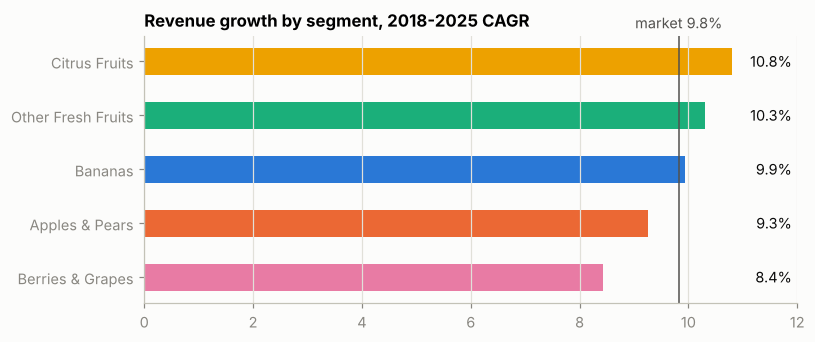

In [ ]:
seg_tbl = pd.DataFrame({
    "revenue_2025_usd_bn": rev_w.loc[SEGS, HIST_END],
    "share_2018_pct": rev_w.loc[SEGS, 2018] / rev_w.loc["Total", 2018] * 100,
    "share_2025_pct": rev_w.loc[SEGS, HIST_END] / rev_w.loc["Total", HIST_END] * 100,
    "revenue_cagr_18_25_pct": [cagr(rev_w.loc[s], 2018, HIST_END) * 100 for s in SEGS],
    "volume_cagr_18_25_pct": [cagr(vol_w.loc[s], 2018, HIST_END) * 100 for s in SEGS],
    "price_2025_usd_kg": prc_w.loc[SEGS, HIST_END],
    "statista_cagr_25_31_pct": [cagr(rev_w.loc[s], HIST_END, 2031) * 100 for s in SEGS],
})
seg_tbl["share_change_pt"] = seg_tbl.share_2025_pct - seg_tbl.share_2018_pct
seg_tbl.loc["Berries & Grapes", "volume_cagr_18_25_pct"] = np.nan    # series break, see 2.2
display(seg_tbl.round(2))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
order = seg_tbl.sort_values("revenue_cagr_18_25_pct").index
ax.barh(order, seg_tbl.loc[order, "revenue_cagr_18_25_pct"], height=0.5, color=[SEG_COL[s] for s in order])
for i, s in enumerate(order):
    ax.text(11.9, i, f"{seg_tbl.loc[s, 'revenue_cagr_18_25_pct']:.1f}%", va="center", ha="right", color=C["ink"])
ax.axvline(hist_cagr * 100, color=C["ink2"], lw=1); ax.text(hist_cagr * 100, len(order) - 0.45, f"market {hist_cagr:.1%}", color=C["ink2"], va="bottom", ha="center")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True); ax.set_xlim(0, 12)
ax.set_title("Revenue growth by segment, 2018-2025 CAGR")
fig.tight_layout(); fig.savefig(OUT / "fig2_segment_growth.png", dpi=200); plt.show()

**Finding 2.** Segment growth rates sit in a narrow band, from 8.4% (Berries & Grapes) to 10.8% (Citrus), and shares moved by about a point or less in seven years. Statista's history is smooth, which is typical of modelled market data: it describes the trend but hides year-to-year shocks. Two consequences. First, segment mix is not where the story is. Second, forecast accuracy measured on this history will look better than it would on real sales data, which matters for section 4.

### 3.3 Channel and Global Context

151 countries in the comparison table (values rounded to whole USD bn)


,china_usd_bn,countries_total_usd_bn,china_share_pct,china_rank,largest_market
2018,57,493,11.60,2.00,India
2025,109,772,14.10,2.00,India
2031,176,1117,15.80,2.00,India


Online share of fresh-fruit revenue across the six unlabelled series, %


,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
lowest series,4.10,5.50,7.60,10.20,10.20,9.70,10.00,10.40,10.20,10.30,15.50,16.00,16.10
median of six,9.10,12.20,17.00,22.90,21.40,18.40,19.80,22.20,23.20,24.70,25.90,26.80,27.00
highest series,14.50,19.30,27.00,36.40,35.00,30.20,33.50,38.50,40.80,44.90,47.50,50.80,52.00


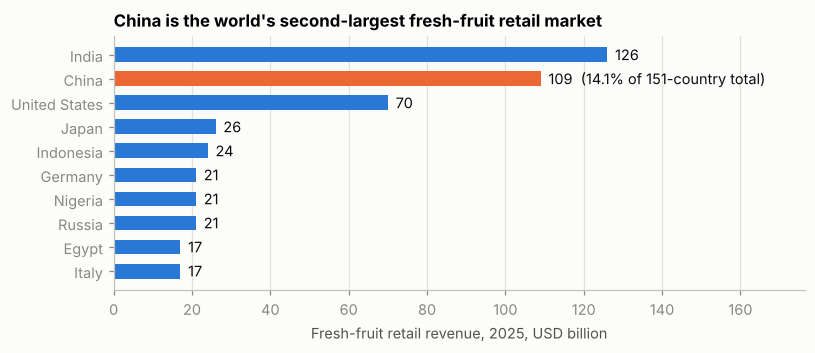

In [ ]:
gc = raw["Global Comparison"]["REVENUE COMPARISON in billion USD (US$)"]
world = gc.sum()
rank = gc.rank(ascending=False, method="min")
glob = pd.DataFrame({"china_usd_bn": gc.loc["China"], "countries_total_usd_bn": world, "china_share_pct": gc.loc["China"] / world * 100,
                     "china_rank": rank.loc["China"], "largest_market": gc.idxmax()}).loc[[2018, HIST_END, 2031]]
print(f"{len(gc)} countries in the comparison table (values rounded to whole USD bn)")
display(glob.round(1))
print("Online share of fresh-fruit revenue across the six unlabelled series, %")
display(channel_summary.round(1).T)

top10 = gc[HIST_END].sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.barh(top10.index[::-1], top10.values[::-1], height=0.62,
        color=[C["orange"] if c == "China" else C["blue"] for c in top10.index[::-1]])
for yy, (c, v) in enumerate(zip(top10.index[::-1], top10.values[::-1])):
    ax.text(v + 2, yy, f"{v:,.0f}" + (f"  ({v / world[HIST_END] * 100:.1f}% of 151-country total)" if c == "China" else ""), va="center", color=C["ink"])
ax.grid(axis="x", color=C["grid"]); ax.grid(axis="y", visible=False); ax.set_axisbelow(True); ax.set_xlim(0, top10.max() * 1.4)
ax.set_xlabel(f"Fresh-fruit retail revenue, {HIST_END}, USD billion")
ax.set_title("China is the world's second-largest fresh-fruit retail market")
fig.tight_layout(); fig.savefig(OUT / "fig8_global_2025.png", dpi=200); plt.show()

**Finding 3.** China is the second-largest fresh-fruit retail market in the table after India and its share of the 151-country total rises from about 12% to 14% between 2018 and 2025. On channels, every series shows the same shape: online share surged to 2021, gave back part of the gain in 2022 and 2023, and is climbing again. For Pagoda this matters because 25.2% of its 2024 orders came through online platforms, almost half of them through Meituan (Xu and Wang 2025), while revenue it books from its own online channel has shrunk to about 1% of the total (Liu and Peng 2026). Demand is moving to a channel where Pagoda depends on third parties.

### 3.4 Pagoda against the market
The market is in USD and Pagoda reports in RMB, so Pagoda's revenue is converted with the workbook's CNY series. Section 2.3 showed that series is a projection, so the result is repeated at 7.2 CNY per USD to see whether the conclusion depends on it. (Actual average rates in 2023 to 2025 were close to 7.1 to 7.2 as far as I know; that figure is not in the project files, so check it against PBoC or SAFE data before citing it.)

**What the ratio is and is not.** Most of Pagoda's revenue is fruit sold to franchisees, which is smaller than what those stores sell to shoppers. The ratio below therefore understates Pagoda's retail market share in level. Its *change over time* is the useful signal. As a cross-check on level, Frost & Sullivan put Pagoda at 1.0% of China's fruit retail sales value in 2021 (Wong 2023), against 1.95% on this proxy for the same year. Frost & Sullivan measure a wider market than Statista's at-home retail definition, so the two are not comparable in level; the report should state which definition a share figure uses.

,pagoda_rmb_mn,market_usd_bn,fx_workbook,share_proxy_pct,share_proxy_pct_at_7.2,pagoda_index_2019,market_index_2019
year,,,,,,,
2019,"8,976.00",60.75,6.91,2.14,2.05,100.00,100.00
2020,"8,854.00",69.26,6.90,1.85,1.78,98.64,114.01
2021,"10,289.00",77.19,6.83,1.95,1.85,114.63,127.06
2022,"11,312.00",83.96,6.81,1.98,1.87,126.02,138.21
2023,"11,391.00",91.10,6.78,1.84,1.74,126.91,149.96
2024,"10,273.00",100.06,6.76,1.52,1.43,114.45,164.71
2025,"8,174.00",109.17,6.73,1.11,1.04,91.07,179.70


2019-2023 growth per year: Pagoda 6.1% vs market 10.7%
Share proxy: 2.14% (2019) -> 1.84% (2023) -> 1.11% (2025)
Revenue if the 2023 share proxy had been held in 2025: RMB 13,558 mn; actual 8,174; gap 5,384


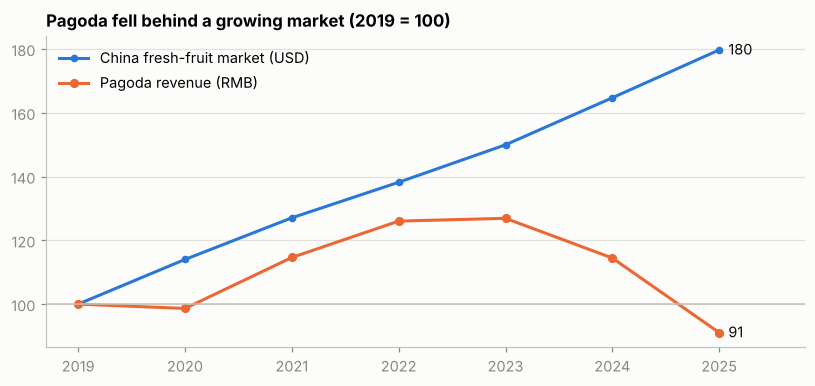

In [ ]:
pg = pagoda[pagoda.metric == "revenue"].set_index("year").value.astype(float)
pg.index = pg.index.astype(int)
share = pd.DataFrame({"pagoda_rmb_mn": pg, "market_usd_bn": tot.revenue_usd_bn[pg.index], "fx_workbook": fx[pg.index]})
share["share_proxy_pct"] = share.pagoda_rmb_mn / share.fx_workbook / 1000 / share.market_usd_bn * 100
share["share_proxy_pct_at_7.2"] = share.pagoda_rmb_mn / 7.2 / 1000 / share.market_usd_bn * 100
share["pagoda_index_2019"] = share.pagoda_rmb_mn / share.pagoda_rmb_mn[2019] * 100
share["market_index_2019"] = share.market_usd_bn / share.market_usd_bn[2019] * 100
display(share.round(2))

pg_cagr_19_23 = cagr(pg, 2019, 2023); mk_cagr_19_23 = cagr(tot.revenue_usd_bn, 2019, 2023)
hold_share_rev = share.share_proxy_pct[2023] / 100 * tot.revenue_usd_bn[HIST_END] * 1000 * fx[HIST_END]
gap = hold_share_rev - pg[HIST_END]
print(f"2019-2023 growth per year: Pagoda {pg_cagr_19_23:.1%} vs market {mk_cagr_19_23:.1%}")
print(f"Share proxy: {share.share_proxy_pct[2019]:.2f}% (2019) -> {share.share_proxy_pct[2023]:.2f}% (2023) -> {share.share_proxy_pct[HIST_END]:.2f}% ({HIST_END})")
print(f"Revenue if the 2023 share proxy had been held in {HIST_END}: RMB {hold_share_rev:,.0f} mn; actual {pg[HIST_END]:,.0f}; gap {gap:,.0f}")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(HIST[1:], tot.revenue_usd_bn[HIST[1:]] / tot.revenue_usd_bn[2019] * 100, color=C["blue"], marker="o", ms=4, label="China fresh-fruit market (USD)")
ax.plot(share.index, share.pagoda_index_2019, color=C["orange"], marker="o", ms=5, label="Pagoda revenue (RMB)")
ax.annotate(f"{share.market_index_2019[HIST_END]:.0f}", (HIST_END, share.market_index_2019[HIST_END]), textcoords="offset points", xytext=(6, -3), color=C["ink"])
ax.annotate(f"{share.pagoda_index_2019[HIST_END]:.0f}", (HIST_END, share.pagoda_index_2019[HIST_END]), textcoords="offset points", xytext=(6, -3), color=C["ink"])
ax.axhline(100, color="#c3c2b7", lw=1); ax.set_xlim(2018.7, 2025.8); ax.legend(loc="upper left")
ax.set_title("Pagoda fell behind a growing market (2019 = 100)")
fig.tight_layout(); fig.savefig(OUT / "fig3_pagoda_vs_market.png", dpi=200); plt.show()

**Finding 4, the core of the analytics opportunity.** Pagoda was losing ground before the 2024 crisis: from 2019 to 2023 it grew about 6% a year while the market grew about 11%. Revenue dipped in 2020, recovered in 2021 and 2022, stalled in 2023 and then fell. The share proxy roughly halves between 2019 and 2025 under either exchange-rate assumption, so the conclusion does not depend on the currency conversion. Had Pagoda only held its 2023 position, 2025 revenue would have been several billion RMB higher. The market did not shrink; Pagoda's position in it did. That points the analytics effort at company levers (stores, sales per store, margin) and not at market forecasting alone. One caution: Frost & Sullivan's market forecast (7.6% a year for 2021 to 2026, cited in CMB 2023) is lower than Statista's history, so the size of the gap depends on the market source, though not its direction.

### 3.5 Pagoda's own numbers: what broke

year,2023,2024,2025
metric,,,
revenue,"11,391.00","10,273.00","8,174.00"
net_profit_attributable,362.00,-386.00,-317.00
gross_margin,11.50,7.40,7.30
selling_expense_ratio,4.20,5.90,6.50
stores_total_year_end,"6,093.00","5,127.00","4,468.00"


,2024,2025,change_pct,share_2025_pct
franchise_stores,"7,396.00","5,912.00",-20.10,72.30
regional_agents,"1,215.00",855.00,-29.60,10.50
self_operated,41.00,21.00,-48.80,0.30
direct_sales,"1,256.00","1,191.00",-5.20,14.60
online,106.00,61.00,-42.50,0.70
other,259.00,134.00,-48.30,1.60


Revenue change 2023->2025: RMB -3,217 mn (-28.2%); stores 6093->4468 (-26.7%)
Gross profit 2023: RMB 1,310 mn; 2025: RMB 597 mn; change -713
  of which lower revenue at the 2023 margin: -370; lower margin on 2025 revenue: -343


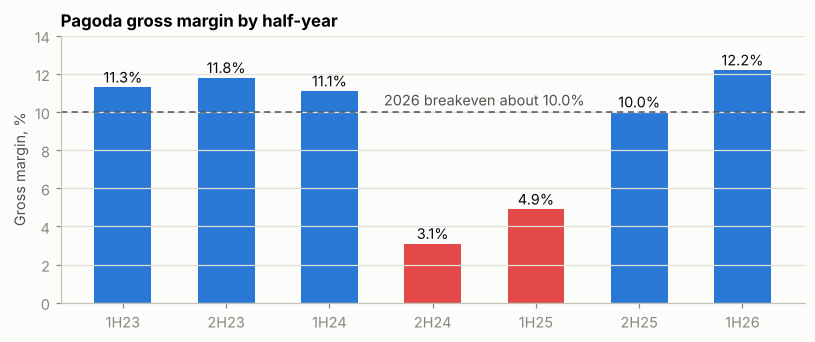

Half-year gross margin, %: {'1H23': 11.3, '2H23': 11.8, '1H24': 11.1, '2H24': 3.1, '1H25': 4.9, '2H25': 10.0, '1H26': 12.2} (1H23-2H24 CICC 2025 p.4; 1H25-1H26 CICC 2026 p.4)


In [ ]:
piv = pagoda[pagoda.year.isin([2023, 2024, 2025])].pivot_table(index="metric", columns="year", values="value", aggfunc="first")
kpi = piv.loc[["revenue", "net_profit_attributable", "gross_margin", "selling_expense_ratio", "stores_total_year_end"]]
display(kpi.round(2))

ch_tbl = pd.DataFrame({y: {c: pagoda[(pagoda.year == y) & (pagoda.metric == f"revenue_{c}")].value.iloc[0] for c in channels} for y in (2024, 2025)})
ch_tbl["change_pct"] = (ch_tbl[2025] / ch_tbl[2024] - 1) * 100
ch_tbl["share_2025_pct"] = ch_tbl[2025] / ch_tbl[2025].sum() * 100
display(ch_tbl.round(1))

rev_drop = pg[2025] - pg[2023]
gp23, gp25 = pg[2023] * 0.115, pg[2025] * 0.073
print(f"Revenue change 2023->2025: RMB {rev_drop:,.0f} mn ({pg[2025] / pg[2023] - 1:.1%}); stores {6093}->{4468} ({4468 / 6093 - 1:.1%})")
print(f"Gross profit 2023: RMB {gp23:,.0f} mn; 2025: RMB {gp25:,.0f} mn; change {gp25 - gp23:,.0f}")
print(f"  of which lower revenue at the 2023 margin: {rev_drop * 0.115:,.0f}; lower margin on 2025 revenue: {pg[2025] * (0.073 - 0.115):,.0f}")

halves = ["1H23", "2H23", "1H24", "2H24", "1H25", "2H25", "1H26"]
gm_half = pd.Series({h: float(pagoda[(pagoda.year == h) & pagoda.metric.isin(["gross_margin_half", "gross_margin_half_cicc"])].value.iloc[-1]) for h in halves})
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bars = ax.bar(gm_half.index, gm_half.values, width=0.55, color=[C["red"] if v < 8 else C["blue"] for v in gm_half.values])
for b_, v in zip(bars, gm_half.values):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 0.25, f"{v:.1f}%", ha="center", color=C["ink"])
ax.axhline(10.0, color=C["ink2"], lw=1, ls=(0, (4, 3))); ax.text(3.5, 10.35, "2026 breakeven about 10.0%", color=C["ink2"], ha="center")
ax.set_ylim(0, 14); ax.set_ylabel("Gross margin, %")
ax.set_title("Pagoda gross margin by half-year")
fig.tight_layout(); fig.savefig(OUT / "fig7_gross_margin_half.png", dpi=200); plt.show()
print("Half-year gross margin, %:", gm_half.to_dict(), "(1H23-2H24 CICC 2025 p.4; 1H25-1H26 CICC 2026 p.4)")

**Finding 5.** Between 2023 and 2025 Pagoda lost about a quarter of its stores and 28% of its revenue, and the gross margin fell from 11.5% to 7.3%. Splitting the fall in gross profit into the two effects shows them to be of similar size: lost revenue and lost margin each removed a few hundred million RMB. Selling expenses rose as a share of revenue at the same time. The second half of 2025 is the first sign of repair: gross margin back to about 10%, sales per store up 1.8% year on year and 85 net new franchise stores (Galaxy 2026). Whether that repair holds is the question the simulator in section 5 puts numbers on.

## 4. Methods and Frameworks: Forecasting the Market

**Why forecast at all, when Statista already provides one?** Because the business case rests on the claim that the market will keep growing, and a vendor forecast with no error bars is a single unexamined assumption. The aim here is to test it: build an independent forecast, measure how accurate simple methods have been, and see whether Statista's path is consistent with them.

**Why simple methods?** There are eight annual observations. Models with many parameters (ARIMA with several lags, gradient boosting, neural networks) cannot be estimated or validated on eight points; they would fit noise. The right tools for a short annual series are low-parameter methods judged by out-of-sample error. Five are compared:

| Method | Idea | Parameters |
|---|---|---|
| Drift | Last value plus the average historical yearly increase (linear growth) | 1 |
| Log-linear trend | Constant growth rate fitted by least squares on log values (exponential growth) | 2 |
| Holt (fixed smoothing) | Level and trend updated each year, recent years weighted more | 2, fixed in advance at 0.8 and 0.2 so nothing is tuned on the test years |
| Driver model | Population x consumption per person x price, each projected separately | 6 |
| Combination | Simple average of Drift and Log-linear trend | none added |

**Validation design.** Rolling-origin evaluation: train on data up to year T, forecast T+1 and T+2, compare with the actual, then move T forward one year. Origins are 2021 to 2024, on the total and all five segments, which gives 42 out-of-sample forecasts per method. A random train/test split would be wrong here because it would let a model see the future.

In [ ]:
def f_drift(y, h):
    return y[-1] + (y[-1] - y[0]) / (len(y) - 1) * np.arange(1, h + 1)

def f_loglinear(y, h):
    t = np.arange(len(y)); b, a = np.polyfit(t, np.log(y), 1)
    return np.exp(a + b * (len(y) - 1 + np.arange(1, h + 1)))

def f_holt(y, h, alpha=0.8, beta=0.2):
    level, trend = y[0], y[1] - y[0]
    for v in y[1:]:
        prev = level
        level = alpha * v + (1 - alpha) * (level + trend)
        trend = beta * (level - prev) + (1 - beta) * trend
    return level + trend * np.arange(1, h + 1)

def f_combination(y, h):
    return (f_drift(y, h) + f_loglinear(y, h)) / 2

def f_driver(seg, train_years, h):
    """Population x per-capita volume x price, each on its own log-linear trend."""
    p = f_loglinear(popn[train_years].values, h)
    q = f_loglinear(mk.loc[seg].volume_per_capita_kg[train_years].values, h)
    pr = f_loglinear(mk.loc[seg].price_usd_per_kg[train_years].values, h)
    return p * q * pr

records = []
for seg in ["Total"] + SEGS:
    y_all = mk.loc[seg].revenue_usd_bn
    for origin in range(2021, HIST_END):
        train = [y for y in HIST if y <= origin]; h = min(2, HIST_END - origin)
        y = y_all[train].values
        preds = {"Drift": f_drift(y, h), "Log-linear trend": f_loglinear(y, h), "Holt (fixed)": f_holt(y, h),
                 "Driver model": f_driver(seg, train, h), "Combination": f_combination(y, h)}
        for m, p in preds.items():
            for k in range(h):
                actual = y_all[origin + k + 1]
                records.append(dict(segment=seg, origin=origin, horizon=k + 1, method=m, forecast=p[k], actual=actual,
                                    ape=abs(p[k] / actual - 1) * 100, pe=(p[k] / actual - 1) * 100))
bt = pd.DataFrame(records)
bt_summary = bt.groupby("method").agg(forecasts=("ape", "size"), mape_pct=("ape", "mean"), worst_error_pct=("ape", "max"), bias_pct=("pe", "mean")).sort_values("mape_pct")
bt_by_h = bt.pivot_table(index="method", columns="horizon", values="ape", aggfunc="mean").add_prefix("mape_h").loc[bt_summary.index]
bt_bias_h = bt.pivot_table(index="method", columns="horizon", values="pe", aggfunc="mean").add_prefix("bias_h").loc[bt_summary.index]
bt_total = bt[bt.segment == "Total"].groupby("method").ape.mean().rename("mape_total_market_pct")
backtest = bt_summary.join(bt_by_h).join(bt_bias_h).join(bt_total)
BEST = backtest.index[0]
print(f"Lowest out-of-sample error: {BEST}")
backtest.round(2)

Lowest out-of-sample error: Combination


,forecasts,mape_pct,worst_error_pct,bias_pct,mape_h1,mape_h2,bias_h1,bias_h2,mape_total_market_pct
method,,,,,,,,,
Combination,42,1.56,5.74,0.71,1.20,2.03,0.60,0.86,0.77
Drift,42,1.96,6.14,-1.41,1.43,2.66,-0.94,-2.04,1.55
Driver model,42,3.03,7.96,2.83,2.34,3.95,2.14,3.75,2.65
Log-linear trend,42,3.08,7.99,2.84,2.38,4.02,2.14,3.77,2.72
Holt (fixed),42,3.57,9.85,-3.53,2.65,4.81,-2.57,-4.81,3.66


**Reading the backtest.**

- The bias columns tell the story. Extrapolating a constant growth *rate* (log-linear, driver model) overshoots by about 3%, because growth rates have eased since the 2020 to 2021 surge. Extrapolating a constant yearly *increase* (drift) undershoots, and the shortfall grows with the horizon. Holt, which weights recent increments most, undershoots more. The market has been growing faster than a straight line and slower than an exponential.
- Averaging the two cancels most of both biases, and the combination has the lowest error. Forecast combination is a standard remedy when candidate models err in opposite directions.
- All errors are small, and that should be read with Finding 2 in mind: the history is a smoothed model output, so these errors are a lower bound on what real sales data would give.

**Forecast range.** With eight observations and test horizons of only one and two years, a statistical prediction interval for a six-year horizon would claim precision the data cannot support. The range reported below is therefore the envelope between the linear and the exponential extrapolation. It expresses disagreement between two defensible models, which is the larger source of uncertainty here, and is labelled as such.

,statista,this_study,linear_path,exponential_path,statista_vs_study_pct,statista_inside_envelope,statista_position_in_envelope_pct
year,,,,,,,
2026,119.40,119.00,116.70,121.40,0.30,True,58.50
2027,127.00,128.90,124.20,133.50,-1.40,True,30.40
2028,136.20,139.30,131.70,146.90,-2.20,True,29.70
2029,145.70,150.40,139.20,161.50,-3.10,True,29.10
2030,161.50,162.20,146.70,177.70,-0.40,True,47.70
2031,176.30,174.80,154.20,195.40,0.90,True,53.70


2031: this study USD 175bn (envelope 154-195); Statista 176bn
Implied 2025-2031 growth: this study 8.2% a year, Statista 8.3%; market added by 2031: USD 45bn to 86bn


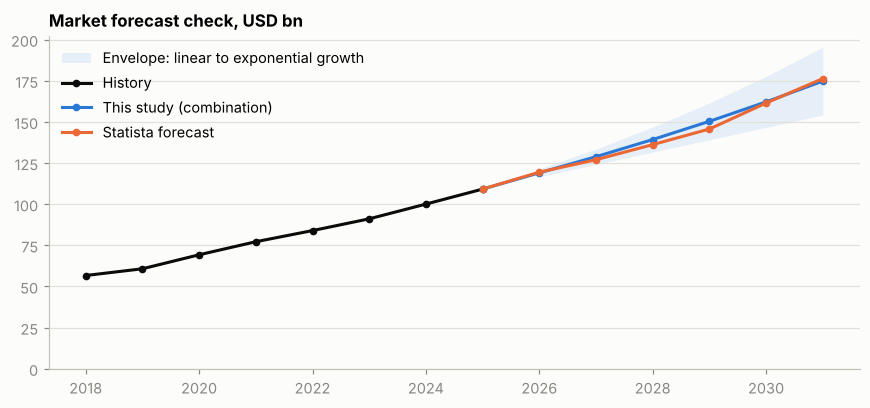

In [ ]:
y_hist = tot.revenue_usd_bn[HIST].values; H = len(FCST)
fc = pd.DataFrame({"statista": tot.revenue_usd_bn[FCST].values, "this_study": f_combination(y_hist, H),
                   "linear_path": f_drift(y_hist, H), "exponential_path": f_loglinear(y_hist, H)}, index=pd.Index(FCST, name="year"))
fc["statista_vs_study_pct"] = (fc.statista / fc.this_study - 1) * 100
fc["statista_inside_envelope"] = (fc.statista >= fc.linear_path) & (fc.statista <= fc.exponential_path)
fc["statista_position_in_envelope_pct"] = (fc.statista - fc.linear_path) / (fc.exponential_path - fc.linear_path) * 100
display(fc.round(1))
study_cagr = (fc.this_study[2031] / y_hist[-1]) ** (1 / H) - 1
print(f"2031: this study USD {fc.this_study[2031]:.0f}bn (envelope {fc.linear_path[2031]:.0f}-{fc.exponential_path[2031]:.0f}); Statista {fc.statista[2031]:.0f}bn")
print(f"Implied {HIST_END}-2031 growth: this study {study_cagr:.1%} a year, Statista {fc_cagr:.1%}; "
      f"market added by 2031: USD {fc.linear_path[2031] - y_hist[-1]:.0f}bn to {fc.exponential_path[2031] - y_hist[-1]:.0f}bn")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(FCST, fc.linear_path, fc.exponential_path, color=C["blue"], alpha=0.10, lw=0, label="Envelope: linear to exponential growth")
ax.plot(HIST, y_hist, color=C["ink"], marker="o", ms=4, label="History")
ax.plot([HIST_END] + FCST, np.r_[y_hist[-1], fc.this_study], color=C["blue"], marker="o", ms=4, label="This study (combination)")
ax.plot([HIST_END] + FCST, np.r_[y_hist[-1], fc.statista], color=C["orange"], marker="o", ms=4, label="Statista forecast")
ax.set_ylim(0); ax.set_xticks(YEARS[::2]); ax.legend(loc="upper left"); ax.set_title("Market forecast check, USD bn")
fig.tight_layout(); fig.savefig(OUT / "fig4_forecast_check.png", dpi=200); plt.show()

**Finding 6.** Statista's forecast stays inside the envelope in every year and ends within 1% of the independent combination forecast in 2031 (USD 176bn against 175bn). There is no evidence against using it as the market assumption in the business case. Its year-to-year shape is less convincing than its level: it runs 1 to 3% below the combination from 2027 to 2029 and catches up through the unexplained price step in 2030 and 2031 (section 2.2). The practical conclusion for Pagoda: even the cautious linear path adds about USD 45bn to the market by 2031. Market growth is not the binding constraint; Pagoda's ability to capture it profitably is.

## 5. Proof of Concept: Turnaround Simulator

### 5.1 Design
Analyst reports give one number per year, and for Pagoda those numbers have a poor record. CMB's 2023 initiation forecast a 2024 net profit of RMB 586 mn; the company lost 386. CICC's forecast for 2025 net profit moved from +220 to -297 within one revision, and its revenue forecast still missed the actual by 11%. A point forecast cannot tell management how likely breakeven is or which lever deserves attention first. A simulation can.

**Model.** Profit is built from the drivers management actually controls:

```
network revenue  = average stores in the year x revenue per store
revenue          = network revenue + direct sales (B2B) + other lines
operating costs  = planned cost x efficiency x [fixed share + (1 - fixed share) x revenue / planned revenue]
net profit       = revenue x gross margin - operating costs - revenue x other net costs
```

- *Network revenue* covers franchised and regional-agent stores, 83% of 2025 revenue. Average stores is the mean of opening and closing counts.
- *Operating costs* are selling plus administrative and R&D expenses. Part of them is fixed, so a revenue shortfall hurts the margin. The fixed share is an assumption (50%) and is stress-tested.
- *Other net costs* (finance costs, tax, minorities, other income) are backed out from Galaxy's forecast so that the model reproduces it.

**Calibration test.** Before any simulation, the model is fed Galaxy's own inputs. If the structure is right it must return Galaxy's revenue and profit.

In [ ]:
BASE = dict(year=2025, stores_end=4460, rev_per_store=1.48, direct=1191.0, other_lines=21 + 61 + 134.0, revenue=8174.0)
SIM_YEARS = [2026, 2027, 2028]
PLAN = GALAXY.copy()
PLAN["store_adds"] = PLAN.stores_end.diff().fillna(PLAN.stores_end.iloc[0] - BASE["stores_end"])
PLAN["rps_growth"] = PLAN.rev_per_store.pct_change().fillna(PLAN.rev_per_store.iloc[0] / BASE["rev_per_store"] - 1)
PLAN["direct_growth"] = PLAN.direct_sales.pct_change().fillna(PLAN.direct_sales.iloc[0] / BASE["direct"] - 1)
PLAN["other_lines"] = PLAN.self_operated + PLAN.online + PLAN.other
PLAN["opex"] = (PLAN.selling + PLAN.admin_rd) * PLAN.revenue
PLAN["other_cost"] = PLAN.gross_margin - PLAN.selling - PLAN.admin_rd - PLAN.net_profit / PLAN.revenue
FIXED_SHARE = 0.5

def profit_model(store_adds, rps_growth, gm, direct_growth, opex_mult, other_cost, fixed_share=FIXED_SHARE):
    """All inputs are arrays of shape (n_trials, 3 years). Returns dict of (n_trials, 3) arrays, RMB mn."""
    store_adds, rps_growth, gm, direct_growth, opex_mult, other_cost = [np.atleast_2d(np.asarray(a, float)) for a in
                                                                        (store_adds, rps_growth, gm, direct_growth, opex_mult, other_cost)]
    stores_end = BASE["stores_end"] + np.cumsum(store_adds, axis=1)
    stores_open = np.column_stack([np.full(len(stores_end), BASE["stores_end"]), stores_end[:, :-1]])
    rps = BASE["rev_per_store"] * np.cumprod(1 + rps_growth, axis=1)
    network = (stores_open + stores_end) / 2 * rps
    direct = BASE["direct"] * np.cumprod(1 + direct_growth, axis=1)
    revenue = network + direct + PLAN.other_lines.values
    opex = PLAN.opex.values * opex_mult * (fixed_share + (1 - fixed_share) * revenue / PLAN.revenue.values)
    net = revenue * gm - opex - revenue * other_cost
    return dict(revenue=revenue, net_profit=net, stores_end=stores_end, network=network, direct=direct, opex=opex)

plan_inputs = dict(store_adds=PLAN.store_adds.values, rps_growth=PLAN.rps_growth.values, gm=PLAN.gross_margin.values,
                   direct_growth=PLAN.direct_growth.values, opex_mult=np.ones(3), other_cost=PLAN.other_cost.values)
chk = profit_model(**plan_inputs)
calib = pd.DataFrame({"galaxy_revenue": PLAN.revenue, "model_revenue": chk["revenue"][0], "galaxy_net_profit": PLAN.net_profit, "model_net_profit": chk["net_profit"][0]})
calib["revenue_gap_pct"] = (calib.model_revenue / calib.galaxy_revenue - 1) * 100
calib["net_profit_gap_rmb_mn"] = calib.model_net_profit - calib.galaxy_net_profit
assert calib.revenue_gap_pct.abs().max() < 0.5
display(calib.round(2))
print("Backed-out 'other net costs' as % of revenue:", (PLAN.other_cost * 100).round(2).tolist())
print(f"Breakeven gross margin at planned revenue: {((PLAN.opex / PLAN.revenue + PLAN.other_cost) * 100).round(2).tolist()} %")

,galaxy_revenue,model_revenue,galaxy_net_profit,model_net_profit,revenue_gap_pct,net_profit_gap_rmb_mn
year,,,,,,
2026,8746,"8,765.94",15,15.98,0.23,0.98
2027,9744,"9,765.18",169,170.29,0.22,1.29
2028,10927,"10,945.77",253,254.23,0.17,1.23


Backed-out 'other net costs' as % of revenue: [0.53, 0.57, 0.68]
Breakeven gross margin at planned revenue: [10.03, 9.27, 9.18] %


The model reproduces Galaxy's revenue within 0.3% and its profit within about RMB 1 mn, so the structure is a fair reading of how the analysts built their case. It also exposes how thin that case is: the planned 2026 gross margin of 10.2% sits less than 0.2 points above the breakeven margin of 10.0%, and 10.0% is where the margin stood in the second half of 2025.

### 5.2 How far off have analyst forecasts been?
Three broker reports in the project made forecasts for years that have since been reported. Comparing each forecast with the actual gives the only empirical evidence available on how much, and in which direction, a plan for Pagoda tends to miss.

In [ ]:
actual = pagoda[pagoda.year.map(lambda v: isinstance(v, int))].pivot_table(index="year", columns="metric", values="value", aggfunc="first")
A = lambda y, m: float(actual.loc[y, m])
cicc_old_gm = 1 - 9570 / 10765                               # CICC 2025 p.4: previous 2025E revenue 10,765 and COGS 9,570
track = pd.DataFrame([
    dict(forecast="CMB, Mar 2023", year=2023, horizon="same year", revenue_f=CMB.revenue[2023], net_profit_f=CMB.net_profit[2023], gm_f=CMB.gross_margin[2023] * 100),
    dict(forecast="CMB, Mar 2023", year=2024, horizon="1 year ahead", revenue_f=CMB.revenue[2024], net_profit_f=CMB.net_profit[2024], gm_f=CMB.gross_margin[2024] * 100),
    dict(forecast="CICC, before Apr 2025", year=2025, horizon="about 1 year ahead", revenue_f=CICC_PREVIOUS_2025E["revenue"], net_profit_f=CICC_PREVIOUS_2025E["net_profit"], gm_f=cicc_old_gm * 100),
    dict(forecast="CICC, Apr 2025", year=2025, horizon="same year", revenue_f=CICC.revenue[2025], net_profit_f=CICC.net_profit[2025], gm_f=CICC.gross_margin[2025] * 100),
])
track["revenue_actual"] = [A(y, "revenue") for y in track.year]
track["revenue_error_pct"] = (track.revenue_actual / track.revenue_f - 1) * 100
track["net_profit_actual"] = [A(y, "net_profit_attributable") for y in track.year]
track["net_profit_error"] = track.net_profit_actual - track.net_profit_f
track["gm_actual"] = [A(y, "gross_margin") for y in track.year]
track["gm_error_pt"] = track.gm_actual - track.gm_f
display(track.round(1))
gm_err_ahead = track.gm_error_pt[track.horizon != "same year"]
print(f"Revenue came in below forecast in {(track.revenue_error_pct < 0).sum()} of {len(track)} cases (mean {track.revenue_error_pct.mean():.0f}%); "
      f"gross margin in {(track.gm_error_pt < 0).sum()} of {len(track)} (mean {track.gm_error_pt.mean():+.1f} pt, mean absolute {track.gm_error_pt.abs().mean():.1f} pt).")
print(f"Gross-margin misses: same-year forecasts {track.gm_error_pt[track.horizon == 'same year'].round(1).tolist()} pt; forecasts made about a year ahead {gm_err_ahead.round(1).tolist()} pt.")
print(f"CMB's 2024 store forecast: {CMB.stores_end[2024]:,} against {A(2024, 'stores_total_year_end'):,.0f} actual ({A(2024, 'stores_total_year_end') / CMB.stores_end[2024] - 1:.0%}).")

,forecast,year,horizon,revenue_f,net_profit_f,gm_f,revenue_actual,revenue_error_pct,net_profit_actual,net_profit_error,gm_actual,gm_error_pt
0,"CMB, Mar 2023",2023,same year,12752,447,12.40,"11,391.00",-10.70,362.00,-85.00,11.50,-0.90
1,"CMB, Mar 2023",2024,1 year ahead,14308,586,12.90,"10,273.00",-28.20,-386.00,-972.00,7.40,-5.50
2,"CICC, before Apr 2025",2025,about 1 year ahead,10765,220,11.10,"8,174.00",-24.10,-317.00,-537.00,7.30,-3.80
3,"CICC, Apr 2025",2025,same year,9176,-297,7.80,"8,174.00",-10.90,-317.00,-20.00,7.30,-0.50


Revenue came in below forecast in 4 of 4 cases (mean -18%); gross margin in 4 of 4 (mean -2.7 pt, mean absolute 2.7 pt).
Gross-margin misses: same-year forecasts [-0.9, -0.5] pt; forecasts made about a year ahead [-5.5, -3.8] pt.
CMB's 2024 store forecast: 7,030 against 5,127 actual (-27%).


Every forecast missed in the same direction. Revenue came in 11% to 28% below forecast, and gross margin 0.5 to 5.5 points below, with the large misses on forecasts made about a year ahead. Four observations on one company during a downturn are not a distribution, but they set the scale: a plus-or-minus one-point range on gross margin would be far too tight, and treating the plan as unbiased is the generous assumption.


### 5.3 Uncertainty Ranges
Each driver gets a triangular distribution: a low, a most-likely and a high value. The **most-likely value is Galaxy's assumption** in every case, so the simulation is anchored on the analysts' base case and adds only the spread. Two sets of ranges are run, because how much to trust an analyst plan is itself a judgement:

- **Neutral.** The plan is as likely to be beaten as missed. Ranges are symmetric, with widths sized from how far each driver has moved in the last two years. Gross margin is given plus or minus 2.5 points, close to the mean absolute forecast miss above (2.7 points). For 2026 that runs from 7.7% to 12.7%: from near the FY2025 level (7.3%) to near the 12.9% CMB once forecast for 2024.
- **Downside-leaning.** The plan is the best realistic case, as the plans for 2023, 2024 and 2025 turned out to be. The low side is set much wider than the high side; for gross margin it sits about 2.7 to 3.0 points below plan, in line with the mean miss.

One draw per driver is applied to all three years, which assumes a team that under-delivers in 2026 also under-delivers in 2027. Section 5.7 tests the alternative.

In [ ]:
DRIVERS = ["store_adds", "rps_growth", "gm", "direct_growth", "opex_mult", "other_cost"]
LABEL = dict(store_adds="Net store openings", rps_growth="Revenue per store growth", gm="Gross margin",
             direct_growth="Direct (B2B) sales growth", opex_mult="Operating cost vs plan", other_cost="Other net costs")
MODE = dict(store_adds=PLAN.store_adds.values, rps_growth=PLAN.rps_growth.values, gm=PLAN.gross_margin.values,
            direct_growth=PLAN.direct_growth.values, opex_mult=np.ones(3), other_cost=PLAN.other_cost.values)
HALF_WIDTH = dict(store_adds=250, rps_growth=0.04, gm=0.025, direct_growth=0.20, opex_mult=0.05, other_cost=0.003)
EVIDENCE = {
    "store_adds": "Net change in network stores per year. 2025: -656, of which 1H25 -741 and 2H25 +85. Plan: +268, +378, +510.",
    "rps_growth": "Revenue per store. 2024: about -10%; 2025: flat; 2H25: +1.8% year on year. Plan: +2% a year.",
    "gm": "Gross margin. 2021: 11.2%; 2023: 11.5%; FY2025: 7.3%; 2H25: about 10%. Analyst forecasts missed by 0.5 to 5.5 points, always low. Plan: 10.2%, 11.0%, 11.5%.",
    "direct_growth": "Direct (B2B) sales growth. 2024: +22%; 2025: -5%. Plan: +30%, +20%, +15%.",
    "opex_mult": "Selling plus administrative and R&D cost against plan. The selling-expense ratio rose in both 2024 and 2025.",
    "other_cost": "Finance costs, tax and other items as % of revenue. Backed out of the plan at 0.5-0.7%; 2024-25 actuals were roughly 0.8-1.2% including one-offs.",
}
DOWNSIDE_LOW_HIGH = dict(   # (low, high) per year; mode stays at plan
    store_adds=([-200, -100, 0], [400, 550, 700]), rps_growth=([-0.04] * 3, [0.05] * 3),
    gm=([0.075, 0.080, 0.085], [0.110, 0.118, 0.123]), direct_growth=([-0.05, 0.0, 0.0], [0.40, 0.30, 0.25]),
    opex_mult=([0.95] * 3, [1.10] * 3), other_cost=((PLAN.other_cost - 0.0025).tolist(), (PLAN.other_cost + 0.0065).tolist()))

def make_ranges(kind, width=1.0):
    if kind == "neutral":
        return {d: dict(low=(MODE[d] - HALF_WIDTH[d] * width).tolist(), mode=MODE[d].tolist(), high=(MODE[d] + HALF_WIDTH[d] * width).tolist()) for d in DRIVERS}
    return {d: dict(low=list(DOWNSIDE_LOW_HIGH[d][0]), mode=MODE[d].tolist(), high=list(DOWNSIDE_LOW_HIGH[d][1])) for d in DRIVERS}

NEUTRAL, DOWNSIDE = make_ranges("neutral"), make_ranges("downside")

def tri_ppf(u, low, mode, high):
    """Inverse CDF of the triangular distribution (arguments broadcast)."""
    u, low, mode, high = np.broadcast_arrays(u, low, mode, high)
    span = high - low; cut = (mode - low) / span
    return np.where(u < cut, low + np.sqrt(u * span * (mode - low)), high - np.sqrt((1 - u) * span * (high - mode)))

def draw_inputs(u, ranges):
    """u: uniforms of shape (n, n_drivers, 3 years) -> dict of (n, 3) driver paths."""
    return {d: tri_ppf(u[:, k, :], np.array(ranges[d]["low"]), np.array(ranges[d]["mode"]), np.array(ranges[d]["high"])) for k, d in enumerate(DRIVERS)}

def simulate(ranges, n=N_TRIALS, seed=SEED, rho=0.0, fixed_share=FIXED_SHARE, persistent=True):
    """Monte Carlo over the six drivers.
    rho: correlation between revenue-per-store growth and gross margin (Gaussian copula).
    persistent: one draw per driver reused in all years (True) or a fresh draw each year (False)."""
    rng = np.random.default_rng(seed)
    z = rng.standard_normal((n, len(DRIVERS), 1 if persistent else 3))
    i, j = DRIVERS.index("rps_growth"), DRIVERS.index("gm")
    z[:, j] = rho * z[:, i] + np.sqrt(1 - rho ** 2) * z[:, j]
    u = np.broadcast_to(stats.norm.cdf(z), (n, len(DRIVERS), 3))
    res = profit_model(**draw_inputs(u, ranges), fixed_share=fixed_share)
    res["u"] = u
    return res

def summarise(sim_):
    def q(a, p): return np.percentile(a, p, axis=0)
    return pd.DataFrame({
        "plan_revenue": PLAN.revenue.values, "revenue_p10": q(sim_["revenue"], 10), "revenue_median": q(sim_["revenue"], 50), "revenue_p90": q(sim_["revenue"], 90),
        "plan_net_profit": PLAN.net_profit.values, "net_profit_p10": q(sim_["net_profit"], 10), "net_profit_median": q(sim_["net_profit"], 50),
        "net_profit_mean": sim_["net_profit"].mean(axis=0), "net_profit_p90": q(sim_["net_profit"], 90),
        "prob_profit_pct": (sim_["net_profit"] > 0).mean(axis=0) * 100}, index=pd.Index(SIM_YEARS, name="year"))

def show_ranges(r):
    t = pd.DataFrame([{"driver": LABEL[d], "year": y, "low": r[d]["low"][k], "most likely (plan)": r[d]["mode"][k], "high": r[d]["high"][k]}
                      for d in DRIVERS for k, y in enumerate(SIM_YEARS)])
    return t.pivot(index="driver", columns="year", values=["low", "most likely (plan)", "high"]).loc[[LABEL[d] for d in DRIVERS]]

with pd.option_context("display.float_format", "{:,.4g}".format):
    print("Neutral ranges"); display(show_ranges(NEUTRAL))
    print("Downside-leaning ranges"); display(show_ranges(DOWNSIDE))
pd.DataFrame({"evidence the range leans on": {LABEL[d]: EVIDENCE[d] for d in DRIVERS}}).style.set_properties(**{"text-align": "left", "white-space": "normal"})

Neutral ranges


low                    most likely (plan)                       high                  
year                          2026      2027     2028               2026     2027     2028     2026     2027     2028
driver                                                                                                               
Net store openings              18       128      260                268      378      510      518      628      760
Revenue per store growth  -0.01973  -0.02013 -0.02052            0.02027  0.01987  0.01948  0.06027  0.05987  0.05948
Gross margin                 0.077     0.085     0.09              0.102     0.11    0.115    0.127    0.135     0.14
Direct (B2B) sales growth   0.1006 0.0001291 -0.04992             0.3006   0.2001   0.1501   0.5006   0.4001   0.3501
Operating cost vs plan        0.95      0.95     0.95                  1        1        1     1.05     1.05     1.05
Other net costs           0.002285  0.002656 0.003846           0.005285 0.005656 0.006846 0.008285 0.008656 0.009846

Downside-leaning ranges


low                   most likely (plan)                      high                
year                          2026     2027     2028               2026     2027     2028    2026    2027    2028
driver                                                                                                           
Net store openings            -200     -100        0                268      378      510     400     550     700
Revenue per store growth     -0.04    -0.04    -0.04            0.02027  0.01987  0.01948    0.05    0.05    0.05
Gross margin                 0.075     0.08    0.085              0.102     0.11    0.115    0.11   0.118   0.123
Direct (B2B) sales growth    -0.05        0        0             0.3006   0.2001   0.1501     0.4     0.3    0.25
Operating cost vs plan        0.95     0.95     0.95                  1        1        1     1.1     1.1     1.1
Other net costs           0.002785 0.003156 0.004346           0.005285 0.005656 0.006846 0.01178 0.01216 0.01335

,evidence the range leans on
Net store openings,"Net change in network stores per year. 2025: -656, of which 1H25 -741 and 2H25 +85. Plan: +268, +378, +510."
Revenue per store growth,Revenue per store. 2024: about -10%; 2025: flat; 2H25: +1.8% year on year. Plan: +2% a year.
Gross margin,"Gross margin. 2021: 11.2%; 2023: 11.5%; FY2025: 7.3%; 2H25: about 10%. Analyst forecasts missed by 0.5 to 5.5 points, always low. Plan: 10.2%, 11.0%, 11.5%."
Direct (B2B) sales growth,"Direct (B2B) sales growth. 2024: +22%; 2025: -5%. Plan: +30%, +20%, +15%."
Operating cost vs plan,Selling plus administrative and R&D cost against plan. The selling-expense ratio rose in both 2024 and 2025.
Other net costs,"Finance costs, tax and other items as % of revenue. Backed out of the plan at 0.5-0.7%; 2024-25 actuals were roughly 0.8-1.2% including one-offs."


### 5.4 Simulation Results

NEUTRAL ranges


year,2026,2027,2028
plan_revenue,"8,746.00","9,744.00","10,927.00"
revenue_p10,"8,550.70","9,238.00","10,064.80"
revenue_median,"8,767.30","9,771.80","10,969.00"
revenue_p90,"8,984.60","10,324.40","11,931.70"
plan_net_profit,15.00,169.00,253.00
net_profit_p10,-106.90,31.60,95.60
net_profit_median,14.90,168.80,252.90
net_profit_mean,15.10,170.00,255.60
net_profit_p90,137.80,308.60,418.60
prob_profit_pct,56.20,94.90,99.00


DOWNSIDE-LEANING ranges


year,2026,2027,2028
plan_revenue,"8,746.00","9,744.00","10,927.00"
revenue_p10,"8,253.70","8,607.10","9,103.90"
revenue_median,"8,522.30","9,229.10","10,122.00"
revenue_p90,"8,763.60","9,799.10","11,075.60"
plan_net_profit,15.00,169.00,253.00
net_profit_p10,-174.40,-74.40,-37.40
net_profit_median,-69.40,49.00,99.70
net_profit_mean,-76.10,42.30,95.60
net_profit_p90,12.00,147.80,219.90
prob_profit_pct,14.20,69.40,82.20


Monte Carlo standard error on the profit probabilities: at most 0.35 points (20,000 trials)
Cumulative 2026-28 net profit, neutral: median RMB 437 mn, P10 21, P90 860; probability positive 91%


Cumulative 2026-28 net profit, downside-leaning: median RMB 80 mn, P10 -283, P90 377; probability positive 61%
Plan (Galaxy) cumulative 2026-28 net profit: RMB 437 mn


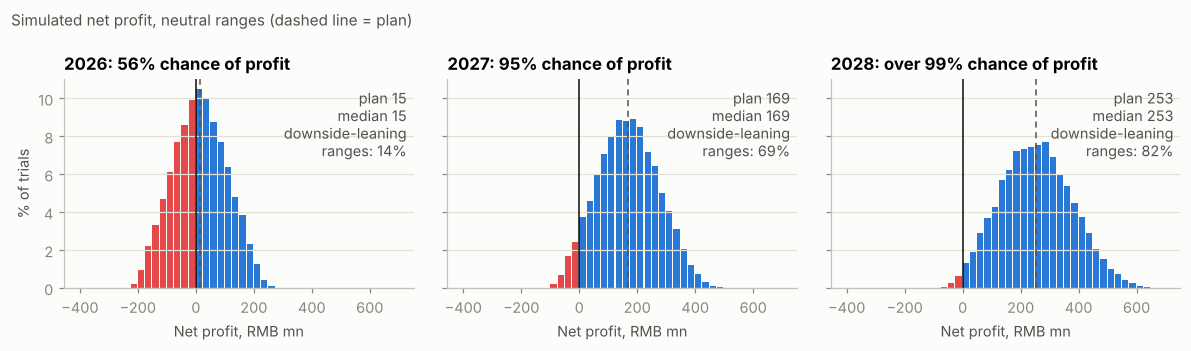

In [ ]:
sim = simulate(NEUTRAL); sim_dn = simulate(DOWNSIDE)
results, results_dn = summarise(sim), summarise(sim_dn)
cum, cum_dn = sim["net_profit"].sum(axis=1), sim_dn["net_profit"].sum(axis=1)
se_prob = np.sqrt(results.prob_profit_pct / 100 * (1 - results.prob_profit_pct / 100) / N_TRIALS) * 100
print("NEUTRAL ranges"); display(results.T.round(1))
print("DOWNSIDE-LEANING ranges"); display(results_dn.T.round(1))
print(f"Monte Carlo standard error on the profit probabilities: at most {se_prob.max():.2f} points ({N_TRIALS:,} trials)")
for name, c in [("neutral", cum), ("downside-leaning", cum_dn)]:
    print(f"Cumulative 2026-28 net profit, {name}: median RMB {np.median(c):,.0f} mn, P10 {np.percentile(c, 10):,.0f}, P90 {np.percentile(c, 90):,.0f}; "
          f"probability positive {(c > 0).mean():.0%}")
print(f"Plan (Galaxy) cumulative 2026-28 net profit: RMB {PLAN.net_profit.sum():,.0f} mn")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
bins = np.linspace(-400, 700, 45)
for k, (ax, y) in enumerate(zip(axes, SIM_YEARS)):
    x = np.clip(sim["net_profit"][:, k], bins[0] + 1, bins[-1] - 1)
    cnt, edges = np.histogram(x, bins=bins)
    ax.bar(edges[:-1], cnt / len(x) * 100, width=np.diff(edges) * 0.86, align="edge", color=np.where(edges[:-1] >= 0, C["blue"], C["red"]))
    ax.axvline(0, color=C["ink"], lw=1); ax.axvline(PLAN.net_profit[y], color=C["ink2"], lw=1, ls=(0, (4, 3)))
    pct = lambda v: "over 99%" if v > 99 else f"{v:.0f}%"
    ax.set_title(f"{y}: {pct(results.prob_profit_pct[y])} chance of profit"); ax.set_xlabel("Net profit, RMB mn")
    ax.text(0.98, 0.95, f"plan {PLAN.net_profit[y]:,.0f}\nmedian {results.net_profit_median[y]:,.0f}\ndownside-leaning\nranges: {pct(results_dn.prob_profit_pct[y])}",
            transform=ax.transAxes, ha="right", va="top", color=C["ink2"])
axes[0].set_ylabel("% of trials")
fig.suptitle("Simulated net profit, neutral ranges (dashed line = plan)", x=0.01, ha="left", fontsize=10, color=C["ink2"])
fig.tight_layout(); fig.savefig(OUT / "fig5_simulation.png", dpi=200); plt.show()

### 5.5 Which lever matters most?
Two views, both under the neutral ranges. The tornado moves one driver from its 10th to its 90th percentile while the others stay at plan, and records the swing in 2027 net profit. The rank correlation reads the same question off the full simulation, where everything moves at once.

2027 net profit with every driver at plan: RMB 170 mn


,profit_at_p10,profit_at_p90,downside,upside,swing,rank_corr,share_of_rank_variance_pct
driver,,,,,,,
Gross margin,35.30,305.20,-135.00,135.00,269.90,0.90,91.60
Operating cost vs plan,193.70,146.80,-23.50,23.50,46.90,-0.20,2.60
Direct (B2B) sales growth,151.10,191.20,-19.10,20.90,40.10,0.10,1.50
Revenue per store growth,150.50,190.50,-19.80,20.20,39.90,0.10,1.80
Net store openings,150.90,189.70,-19.40,19.40,38.80,0.10,1.30
Other net costs,186.50,154.10,-16.20,16.20,32.40,-0.10,1.10


Gross margin's share of rank variance: 92% (neutral), 80% (downside-leaning)


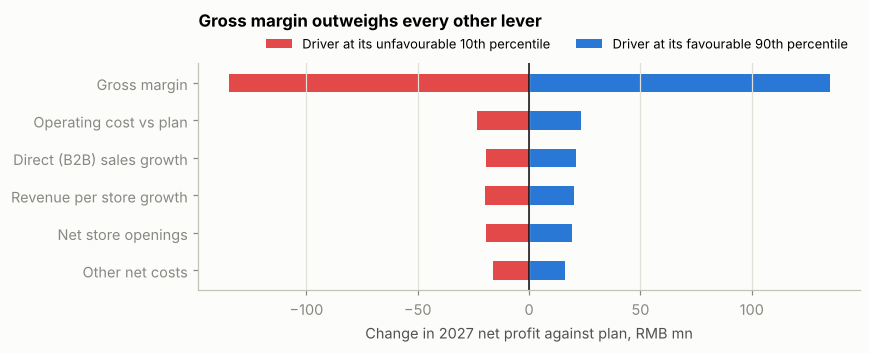

In [ ]:
def tornado_table(ranges, sim_, year_idx=1):
    u_mode = np.array([[(ranges[d]["mode"][year_idx] - ranges[d]["low"][year_idx]) / (ranges[d]["high"][year_idx] - ranges[d]["low"][year_idx]) for d in DRIVERS]])
    def np_at(u_row):
        return profit_model(**draw_inputs(np.repeat(u_row[:, :, None], 3, axis=2), ranges))["net_profit"][0, year_idx]
    base = np_at(u_mode); rows = []
    for k, d in enumerate(DRIVERS):
        lo, hi = u_mode.copy(), u_mode.copy(); lo[0, k], hi[0, k] = 0.10, 0.90
        v_lo, v_hi = np_at(lo), np_at(hi)
        rho_s = stats.spearmanr(sim_["u"][:, k, 0], sim_["net_profit"][:, year_idx]).statistic
        rows.append(dict(driver=LABEL[d], profit_at_p10=v_lo, profit_at_p90=v_hi, downside=min(v_lo, v_hi) - base, upside=max(v_lo, v_hi) - base,
                         swing=abs(v_hi - v_lo), rank_corr=rho_s))
    t = pd.DataFrame(rows).set_index("driver").sort_values("swing", ascending=False)
    t["share_of_rank_variance_pct"] = t.rank_corr ** 2 / (t.rank_corr ** 2).sum() * 100
    return base, t

base_np, tornado = tornado_table(NEUTRAL, sim)
_, tornado_dn = tornado_table(DOWNSIDE, sim_dn)
print(f"2027 net profit with every driver at plan: RMB {base_np:,.0f} mn")
display(tornado.round(1))
print(f"Gross margin's share of rank variance: {tornado.share_of_rank_variance_pct['Gross margin']:.0f}% (neutral), "
      f"{tornado_dn.share_of_rank_variance_pct['Gross margin']:.0f}% (downside-leaning)")

fig, ax = plt.subplots(figsize=(8, 3.3))
order = tornado.index[::-1]
ax.barh(order, tornado.loc[order, "downside"], height=0.5, color=C["red"], label="Driver at its unfavourable 10th percentile")
ax.barh(order, tornado.loc[order, "upside"], height=0.5, color=C["blue"], label="Driver at its favourable 90th percentile")
ax.axvline(0, color=C["ink"], lw=1); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Change in 2027 net profit against plan, RMB mn"); ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncols=2, fontsize=8.5)
ax.set_title("Gross margin outweighs every other lever", pad=24)
fig.tight_layout(); fig.savefig(OUT / "fig6_tornado.png", dpi=200); plt.show()

### 5.6 Lever Equivalence and Breakeven
How many stores is one point of gross margin worth? The comparison uses 2027, when stores opened during 2026 have traded for a full year.

In [ ]:
def np_2027(**override):
    inp = {k: np.array(v, float).copy() for k, v in plan_inputs.items()}
    for k, (idx, delta) in override.items():
        inp[k][idx] += delta
    return profit_model(**inp)["net_profit"][0, 1]

d_gm = np_2027(gm=(slice(None), 0.01)) - np_2027()                 # +1 pt gross margin in every year
d_store = (np_2027(store_adds=(0, 100)) - np_2027()) / 100          # one more store opened in 2026, effect on 2027
d_rps = np_2027(rps_growth=(0, 0.01)) - np_2027()                   # +1 pt revenue per store growth in 2026
levers = pd.Series({"+1 pt gross margin": d_gm, "+1 pt revenue per store": d_rps, "+100 net stores": d_store * 100}, name="effect on 2027 net profit, RMB mn")
display(levers.round(1).to_frame())
stores_per_gm_point = d_gm / d_store
print(f"One point of gross margin is worth as much 2027 profit as about {stores_per_gm_point:,.0f} extra stores "
      f"({stores_per_gm_point / BASE['stores_end']:.0%} of today's network).")

be = pd.DataFrame({"breakeven_gm_pct": (PLAN.opex / PLAN.revenue + PLAN.other_cost) * 100, "plan_gm_pct": PLAN.gross_margin * 100})
be["headroom_pt"] = be.plan_gm_pct - be.breakeven_gm_pct
display(be.round(2))

,"effect on 2027 net profit, RMB mn"
+1 pt gross margin,97.70
+1 pt revenue per store,4.50
+100 net stores,9.40


One point of gross margin is worth as much 2027 profit as about 1,042 extra stores (23% of today's network).


,breakeven_gm_pct,plan_gm_pct,headroom_pt
year,,,
2026,10.03,10.20,0.17
2027,9.27,11.00,1.73
2028,9.18,11.50,2.32


### 5.7 Robustness of the simulation
Several assumptions cannot be observed in the data: the fixed share of operating costs, whether sales per store and gross margin move together, whether a bad year carries over, and how wide the ranges should be. Each is varied in turn. A conclusion is only reported in the findings if it survives all of them.

In [ ]:
def scenario(label, ranges=NEUTRAL, **kw):
    s = simulate(ranges, **kw); cumul = s["net_profit"].sum(axis=1)
    _, t = tornado_table(ranges, s) if kw.get("persistent", True) else (None, None)
    return dict(scenario=label, **{f"prob_profit_{y}_pct": (s["net_profit"][:, k] > 0).mean() * 100 for k, y in enumerate(SIM_YEARS)},
                median_cum_profit=np.median(cumul), prob_cum_positive_pct=(cumul > 0).mean() * 100,
                top_driver=(t.share_of_rank_variance_pct.idxmax() if t is not None else "n/a"),
                top_driver_share_pct=(t.share_of_rank_variance_pct.max() if t is not None else np.nan))

robust = pd.DataFrame([
    scenario("Neutral base (costs 50% fixed, no correlation, persistent draws)"),
    scenario("Operating costs 25% fixed", fixed_share=0.25),
    scenario("Operating costs 75% fixed", fixed_share=0.75),
    scenario("Price cuts trade margin for sales (correlation -0.5)", rho=-0.5),
    scenario("Strong demand lifts both (correlation +0.5)", rho=0.5),
    scenario("Fresh draw every year (no carry-over)", persistent=False),
    scenario("Neutral ranges 50% wider", ranges=make_ranges("neutral", 1.5)),
    scenario("Neutral ranges 50% narrower", ranges=make_ranges("neutral", 0.5)),
    scenario("Downside-leaning ranges", ranges=DOWNSIDE),
]).set_index("scenario")
display(robust.round(1))
print(f"Probability of a 2026 profit across all scenarios: {robust.prob_profit_2026_pct.min():.0f}% to {robust.prob_profit_2026_pct.max():.0f}%")
print("Top driver in every scenario where it can be ranked:", sorted(set(robust.top_driver) - {"n/a"}))

,prob_profit_2026_pct,prob_profit_2027_pct,prob_profit_2028_pct,median_cum_profit,prob_cum_positive_pct,top_driver,top_driver_share_pct
scenario,,,,,,,
"Neutral base (costs 50% fixed, no correlation, persistent draws)",56.20,94.90,99.00,436.80,91.30,Gross margin,91.60
Operating costs 25% fixed,56.10,95.00,99.30,435.60,91.60,Gross margin,94.40
Operating costs 75% fixed,56.20,94.60,98.50,438.40,91.00,Gross margin,87.80
Price cuts trade margin for sales (correlation -0.5),56.10,95.80,99.60,435.60,92.60,Gross margin,81.70
Strong demand lifts both (correlation +0.5),56.10,93.80,98.30,437.60,90.00,Gross margin,70.80
Fresh draw every year (no carry-over),56.70,95.10,99.30,439.30,99.30,n/a,NaN
Neutral ranges 50% wider,54.00,85.10,91.80,434.60,81.20,Gross margin,91.70
Neutral ranges 50% narrower,62.80,100.00,100.00,438.70,100.00,Gross margin,91.60
Downside-leaning ranges,14.20,69.40,82.20,80.40,61.40,Gross margin,80.10


Probability of a 2026 profit across all scenarios: 14% to 63%
Top driver in every scenario where it can be ranked: ['Gross margin']


**Finding 7, the proof-of-concept result.**

- **2026 is a breakeven year at best.** If the analyst plan is unbiased, the chance of a 2026 profit is about 56%. If the plan is the best realistic case, as the plans for 2023, 2024 and 2025 all turned out to be, it is about 14%. Across every variant tested the range is 14% to 63%. The plan's RMB 15 mn for 2026 is best read as "about zero".
- **From 2027 the question is whether the plan is biased.** Under neutral ranges a 2027 profit is likely (about 95%), because the plan has gross margin rising to 11.0% against a breakeven of 9.3%. Under downside-leaning ranges it drops to 69%, and the three-year cumulative profit is positive in 61% of trials instead of 91%. The forecast record in section 5.2 favours the downside-leaning view; the simulation shows what each view implies and what to monitor.
- **Gross margin is the lever.** It carries 80% to 92% of the variation in 2027 profit depending on the ranges, and is the top driver in every robustness scenario. One point of gross margin is worth about RMB 98 mn of 2027 profit, the same as roughly 1,040 additional stores, nearly a quarter of today's network. Pagoda earns a thin wholesale margin on each store's sales, so adding stores adds little profit.
- **Store growth, the headline of the analyst case, matters least for profit in this horizon.** 100 net new stores add about RMB 9 mn. Store growth matters for revenue and for the equity story, not for getting back to breakeven.

**So what for the capstone.** The analytics investment with the highest return is whatever protects or lifts gross margin, and the evidence says where to look first.

1. **Pricing and grade mix.** Pagoda prices by quality grade: Excellent-grade fruit sold at RMB 20 to 25 per kg in 2019 to 2021 against 13 to 15 for Grade A (CMB 2023). The 2023 analyst case for margin expansion rested on selling more Excellent-grade fruit; the 2024 move to "quality at value" pricing reversed it, and both later reports attribute the margin fall to that choice. Analytics that shows which products to discount, by how much, and what each promotion does to traffic and margin acts on the stated cause.
2. **Procurement and product mix.** Fruit cost is about 95% of cost of goods (CMB 2023), so buying and grading decisions are where a wholesaler's margin is made.
3. **Demand forecasting as the enabler, not the fix.** Franchisees buy fruit from Pagoda and pay a royalty on their own gross profit; royalties were 1.6% of Pagoda's 2021 revenue, and Pagoda itself holds about 10 days of stock. Store-level spoilage therefore lands mainly on franchisees. Better forecasts help Pagoda indirectly, through healthier franchisees and fewer closures, and they are a necessary input to pricing and buying. The source does not describe the returns policy between Pagoda and its franchisees, so this reading should be confirmed in the annual report.

Half a point of margin lifts the chance of a 2026 profit from 56% to 73% under neutral ranges and from 14% to 35% under downside-leaning ones. These programmes need Pagoda's internal sales, pricing and waste data, which is the scale-up step. The simulator built here is the tool that sizes the prize and tracks whether the turnaround is on course.

### 5.8 Out-of-sample check: what the first half of 2026 says about the simulator
CICC's results review of 7 September 2026 reports Pagoda's first-half 2026 results, which came out after the Galaxy plan used to calibrate the simulator (April 2026). This is the first chance to test the simulator's assumptions against outcomes it did not see. Half-year figures are not full-year figures, so the test asks a narrower question: where in each assumed range did the first half land?

In [ ]:
def tri_cdf(x, lo, mode, hi):
    """Share of a triangular distribution below x."""
    if x <= lo: return 0.0
    if x >= hi: return 1.0
    return (x - lo) ** 2 / ((hi - lo) * (mode - lo)) if x <= mode else 1 - (hi - x) ** 2 / ((hi - lo) * (hi - mode))

F = lambda period, metric: float(pagoda[(pagoda.year == period) & (pagoda.metric == metric)].value.iloc[0])
gm_h1, gm_core = F("1H26", "gross_margin_half_cicc") / 100, F("1H26", "gross_margin_excluding_alliance") / 100
adds_h1 = F("1H26", "stores_franchise_network_period_end") - BASE["stores_end"]
sales_store = F("1H26", "daily_sales_per_store_growth_yoy") / 100

def pctl(ranges, d, x):
    r = ranges[d]; return tri_cdf(x, r["low"][0], r["mode"][0], r["high"][0]) * 100

check = pd.DataFrame([
    dict(driver="Gross margin", plan_2026=PLAN.gross_margin[2026] * 100, first_half_2026=gm_h1 * 100,
         percentile_in_neutral_range=pctl(NEUTRAL, "gm", gm_h1), percentile_in_downside_range=pctl(DOWNSIDE, "gm", gm_h1),
         note=f"{gm_core:.1%} excluding the Seven-Star alliance (CICC estimate)"),
    dict(driver="Net store openings", plan_2026=PLAN.store_adds[2026], first_half_2026=adds_h1,
         percentile_in_neutral_range=pctl(NEUTRAL, "store_adds", adds_h1), percentile_in_downside_range=pctl(DOWNSIDE, "store_adds", adds_h1),
         note="six months only, against full-year ranges; second-half closures could offset"),
    dict(driver="Sales per store growth", plan_2026=PLAN.rps_growth[2026] * 100, first_half_2026=sales_store * 100,
         percentile_in_neutral_range=pctl(NEUTRAL, "rps_growth", sales_store), percentile_in_downside_range=pctl(DOWNSIDE, "rps_growth", sales_store),
         note="store-level daily sales, not Pagoda revenue per store; definitions differ"),
]).set_index("driver")
display(check.round(1))

rev_h1, rev_h1_25 = F("1H26", "revenue_half"), F("1H25", "revenue_half")
alliance = F("1H26", "seven_star_alliance_revenue")
core_growth = (rev_h1 - alliance) / rev_h1_25 - 1
h2_rev = CICC_SEP26.revenue[2026] - rev_h1
h2_gm = ((CICC_SEP26.revenue[2026] - CICC_SEP26.cogs[2026]) - F("1H26", "gross_profit_half")) / h2_rev
h2_adj_np = CICC_SEP26.net_profit[2026] - F("1H26", "adjusted_net_profit_half")
print(f"1H26 revenue {rev_h1:,.0f} (+{rev_h1 / rev_h1_25 - 1:.1%} YoY), of which the Seven-Star alliance {alliance:,.0f} ({alliance / rev_h1:.0%}). "
      f"Excluding the alliance, revenue changed {core_growth:+.1%} YoY.")
print(f"1H26 net profit {F('1H26', 'net_profit_half'):+.0f} (adjusted {F('1H26', 'adjusted_net_profit_half'):+.0f}) against a full-year 2026 plan of {PLAN.net_profit[2026]:+.0f} (Galaxy).")
np_h1 = 33.6   # profit attributable, Pagoda 2026b interim results (CICC 2026 rounds it to 34)
reach_n, reach_d = (sim["net_profit"][:, 0] >= np_h1).mean() * 100, (sim_dn["net_profit"][:, 0] >= np_h1).mean() * 100
print(f"Share of trials whose FULL-YEAR 2026 profit reaches the first half's RMB {np_h1} mn: {reach_n:.0f}% (neutral), {reach_d:.0f}% (downside-leaning).")
print(f"Store basis: the model counts the franchise network (franchised + regional-agent stores): {F('1H26', 'stores_franchise_network_period_end'):,.0f} at end-June "
      f"(CICC 2026), +{adds_h1:,.0f} on {BASE['stores_end']:,} at end-2025, against a planned year-end {PLAN.stores_end[2026]:,}. "
      "Pagoda's own total of 4,758 (Pagoda 2026b) includes self-operated stores and compares with 4,468 at end-2025 (+290).")
print(f"CICC's updated full-year 2026 forecast implies a second half with revenue {h2_rev:,.0f}, gross margin {h2_gm:.1%} and adjusted net profit {h2_adj_np:+.0f}.")

,plan_2026,first_half_2026,percentile_in_neutral_range,percentile_in_downside_range,note
driver,,,,,
Gross margin,10.20,12.20,98.00,100.00,12.9% excluding the Seven-Star alliance (CICC ...
Net store openings,268.00,292.00,59.10,85.30,"six months only, against full-year ranges; sec..."
Sales per store growth,2.00,1.40,35.60,53.80,"store-level daily sales, not Pagoda revenue pe..."


1H26 revenue 5,008 (+14.4% YoY), of which the Seven-Star alliance 721 (14%). Excluding the alliance, revenue changed -2.0% YoY.
1H26 net profit +34 (adjusted +61) against a full-year 2026 plan of +15 (Galaxy).
Share of trials whose FULL-YEAR 2026 profit reaches the first half's RMB 33.6 mn: 42% (neutral), 4% (downside-leaning).
Store basis: the model counts the franchise network (franchised + regional-agent stores): 4,752 at end-June (CICC 2026), +292 on 4,460 at end-2025, against a planned year-end 4,728. Pagoda's own total of 4,758 (Pagoda 2026b) includes self-operated stores and compares with 4,468 at end-2025 (+290).
CICC's updated full-year 2026 forecast implies a second half with revenue 5,278, gross margin 9.3% and adjusted net profit +58.


**Finding 8, the first out-of-sample test.**

- **The margin lever moved first, and in Pagoda's favour.** First-half gross margin was 12.2%, above the plan's 10.2%, above every forecast on record and near the top of the neutral range. It is above the whole downside-leaning range for 2026. CICC attributes the gain to "optimization of the fruit product mix" (CICC 2026, p.1), which is the lever this analysis ranked first. This supports the recommendation; it does not prove it, because one half-year is a single observation.
- **The downside-leaning view is now hard to defend for 2026, though not yet for 2027 and 2028.** Pagoda earned RMB 34 mn net (61 adjusted) in the first half, more than the plan's full-year 15. Only about 42% of neutral trials and 4% of downside-leaning trials reach that much profit for the full year. A 2026 loss now needs a second-half loss larger than that. The second half of 2025 was profitable at a 10.0% margin.
- **Stores are ahead of plan.** The franchise network grew by 292 stores in six months against a full-year plan of 268 (on Pagoda's total-store basis, which includes self-operated stores, 4,758 against 4,468, or +290), with 45% of new stores in tier-3 and smaller cities (CICC 2026, p.1).
- **The revenue story has changed shape.** About 14% of first-half revenue came from the Seven-Star Convention Alliance, seven regional retail brands supplied by Pagoda, at an estimated 7.7% gross margin. Excluding it, revenue fell about 2% year on year. The simulator has no driver for this business, so its revenue is no longer like-for-like with reported revenue. Adding an alliance driver is the main model change the new information calls for.
- **Analysts still expect the margin to slip.** CICC's updated full-year forecast implies a second-half gross margin of about 9.3%, below the first half, as the lower-margin alliance grows. That is the next test of the model.

The simulator's ranges are left unchanged so its results stay comparable with earlier versions; this check is reported alongside them. Re-calibrating to CICC's September forecast would require store and per-store assumptions that the report does not give.

### 5.9 How the proof of concept (POC) is built
Five layers, from raw files to the people who use the answers. The same calculation code runs in this notebook and in the live Streamlit app, and the app's engine is checked against this notebook value by value.

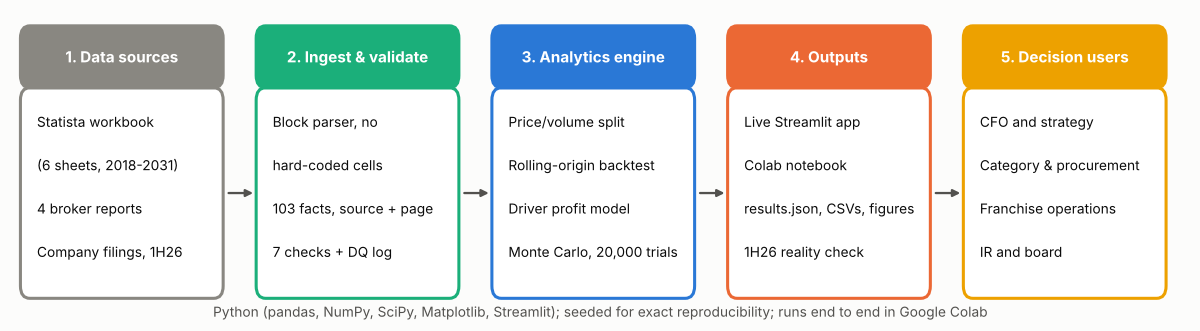

In [ ]:
from matplotlib.patches import FancyBboxPatch
layers = [("1. Data sources", ["Statista workbook", "(6 sheets, 2018-2031)", "4 broker reports", "Company filings, 1H26"], C["muted"]),
          ("2. Ingest & validate", ["Block parser, no", "hard-coded cells", "103 facts, source + page", "7 checks + DQ log"], C["aqua"]),
          ("3. Analytics engine", ["Price/volume split", "Rolling-origin backtest", "Driver profit model", "Monte Carlo, 20,000 trials"], C["blue"]),
          ("4. Outputs", ["Live Streamlit app", "Colab notebook", "results.json, CSVs, figures", "1H26 reality check"], C["orange"]),
          ("5. Decision users", ["CFO and strategy", "Category & procurement", "Franchise operations", "IR and board"], C["yellow"])]
fig, ax = plt.subplots(figsize=(11, 3.1)); ax.set_axis_off(); ax.set_xlim(0, 5); ax.set_ylim(0, 1)
for k, (head, lines, col) in enumerate(layers):
    x0 = k + 0.05
    ax.add_patch(FancyBboxPatch((x0, 0.08), 0.84, 0.66, boxstyle="round,pad=0.01,rounding_size=0.04", fc="white", ec=col, lw=2))
    ax.add_patch(FancyBboxPatch((x0, 0.76), 0.84, 0.18, boxstyle="round,pad=0.01,rounding_size=0.04", fc=col, ec=col, lw=2))
    ax.text(x0 + 0.42, 0.85, head, ha="center", va="center", color="white", fontweight="bold", fontsize=10)
    for j, line in enumerate(lines):
        ax.text(x0 + 0.06, 0.64 - j * 0.14, line, ha="left", va="center", color=C["ink"], fontsize=9)
    if k < 4:
        ax.annotate("", xy=(k + 1.04, 0.41), xytext=(k + 0.91, 0.41), arrowprops=dict(arrowstyle="-|>", color=C["ink2"], lw=1.5))
ax.text(2.5, 0.0, "Python (pandas, NumPy, SciPy, Matplotlib, Streamlit); seeded for exact reproducibility; runs end to end in Google Colab",
        ha="center", va="bottom", color=C["ink2"], fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "fig0_architecture.png", dpi=200); plt.show()

## 6. Business Value: Figures for the Cost-Benefit Section
The benefit side is sized from the model. The cost side is a pilot estimate built from Shenzhen salary benchmarks plus stated team assumptions, set out line by line below so each can be challenged.

In [ ]:
rev26 = float(chk["revenue"][0, 0])
def with_margin_lift(ranges, lift):
    r = {d: dict(v) for d, v in ranges.items()}
    r["gm"] = {k: (np.array(v) + lift).tolist() for k, v in ranges["gm"].items()}
    return simulate(r)

lift_n, lift_d = with_margin_lift(NEUTRAL, 0.005), with_margin_lift(DOWNSIDE, 0.005)
value = pd.Series({
    "2026 revenue at plan, RMB mn": rev26,
    "Profit from +1.0 pt gross margin, per year at 2026 revenue, RMB mn": rev26 * 0.01,
    "Profit from +0.5 pt gross margin, per year, RMB mn": rev26 * 0.005,
    "Profit from +0.1 pt gross margin, per year, RMB mn": rev26 * 0.001,
    "Gross margin needed to break even in 2026, %": be.breakeven_gm_pct[2026],
    "Gross-margin headroom in the 2026 plan, pt": be.headroom_pt[2026],
    "Probability of 2026 profit, neutral, %": results.prob_profit_pct[2026],
    "Probability of 2026 profit with +0.5 pt margin, neutral, %": (lift_n["net_profit"][:, 0] > 0).mean() * 100,
    "Probability of 2026 profit, downside-leaning, %": results_dn.prob_profit_pct[2026],
    "Probability of 2026 profit with +0.5 pt margin, downside-leaning, %": (lift_d["net_profit"][:, 0] > 0).mean() * 100,
    "Median 2026-28 cumulative profit, neutral, RMB mn": np.median(cum),
    "Median 2026-28 cumulative profit with +0.5 pt margin, neutral, RMB mn": np.median(lift_n["net_profit"].sum(axis=1)),
})
with pd.option_context("display.max_colwidth", 120):
    display(value.round(1).to_frame("value"))

# Value of gross-margin improvement (report Table 15): the same lift applied to every year
uplift_rows = []
for lift in [0.0, 0.001, 0.003, 0.005, 0.01]:
    n_, d_ = (sim, sim_dn) if lift == 0 else (with_margin_lift(NEUTRAL, lift), with_margin_lift(DOWNSIDE, lift))
    uplift_rows.append(dict(uplift_pt=lift * 100, profit_per_year_rmb_mn=rev26 * lift,
                            p_profit_2026_neutral_pct=(n_["net_profit"][:, 0] > 0).mean() * 100,
                            p_profit_2026_downside_pct=(d_["net_profit"][:, 0] > 0).mean() * 100,
                            median_cumulative_neutral_rmb_mn=np.median(n_["net_profit"].sum(axis=1))))
uplift = pd.DataFrame(uplift_rows).set_index("uplift_pt")
display(uplift.round(1))

# Pilot cost estimate: 6 months, about 100 stores in two regions
PILOT_MONTHS, PILOT_STORES = 6, 100
team = pd.DataFrame([
    ("Analytics lead / data scientist", 1.0, 430_000, "sourced", "Levels.fyi 2026: Shenzhen data scientist median CN¥426,827 (23 submissions)"),
    ("Data analyst", 2.0, 200_000, "judgement", "Levels.fyi 2026 Shenzhen median 133k, China 313k; Payscale 2025 China base 155k"),
    ("Data engineer", 1.0, 350_000, "judgement", "Between Payscale 2025 Shenzhen developer base 191k and Levels.fyi 2026 Shenzhen software engineer 506k"),
    ("Solution architect (part time)", 0.5, 650_000, "judgement", "Levels.fyi 2026: about 710k Shenzhen, 716k China median (10 submissions)"),
], columns=["role", "fte", "annual_pay_rmb", "basis", "source"])
team["cost_rmb_mn"] = team.fte * team.annual_pay_rmb * PILOT_MONTHS / 12 / 1e6
salaries = team.cost_rmb_mn.sum()
ON_COST, TOOLS, STORE_TESTS, CONTINGENCY = 0.30, 0.30, 0.50, 0.15
pilot_cost = pd.concat([team[["role", "basis", "source", "cost_rmb_mn"]].rename(columns={"role": "item"}), pd.DataFrame([
    ("Employer social insurance and housing fund (30% of salary)", "judgement", "Assumption", salaries * ON_COST),
    ("Tools and cloud", "judgement", "Assumption", TOOLS),
    (f"Store tests and franchisee loss guarantees ({PILOT_STORES} stores)", "judgement", "Assumption", STORE_TESTS),
], columns=["item", "basis", "source", "cost_rmb_mn"])], ignore_index=True)
subtotal = pilot_cost.cost_rmb_mn.sum()
pilot_cost.loc[len(pilot_cost)] = ("Contingency (15%)", "judgement", "Assumption", subtotal * CONTINGENCY)
pilot_total = pilot_cost.cost_rmb_mn.sum()
run_cost = salaries * (1 + ON_COST) * 12 / PILOT_MONTHS + TOOLS * 12 / PILOT_MONTHS
pt_value = rev26 / 100                                         # RMB mn of profit per point of margin, per year
pilot_share = PILOT_STORES / F("1H26", "stores_franchise_network_period_end")
with pd.option_context("display.max_colwidth", 110):
    display(pilot_cost.round(3))
print(f"Pilot cost about RMB {pilot_total:.1f} mn; network-wide break-even about {pilot_total / pt_value:.2f} pt of margin.")
print(f"If the team is kept after rollout: running cost about RMB {run_cost:.1f} mn a year, break-even about {run_cost / pt_value:.2f} pt.")
print(f"The pilot alone: {PILOT_STORES} stores are about {pilot_share:.0%} of the network, so +0.3 pt in them is worth about RMB {0.3 * pt_value * pilot_share * PILOT_MONTHS / 12:.1f} mn over the pilot; network-wide +0.3 pt is worth RMB {0.3 * pt_value:.0f} mn a year.")

,value
"2026 revenue at plan, RMB mn","8,765.90"
"Profit from +1.0 pt gross margin, per year at 2026 revenue, RMB mn",87.70
"Profit from +0.5 pt gross margin, per year, RMB mn",43.80
"Profit from +0.1 pt gross margin, per year, RMB mn",8.80
"Gross margin needed to break even in 2026, %",10.00
"Gross-margin headroom in the 2026 plan, pt",0.20
"Probability of 2026 profit, neutral, %",56.20
"Probability of 2026 profit with +0.5 pt margin, neutral, %",72.60
"Probability of 2026 profit, downside-leaning, %",14.20
"Probability of 2026 profit with +0.5 pt margin, downside-leaning, %",35.40


,profit_per_year_rmb_mn,p_profit_2026_neutral_pct,p_profit_2026_downside_pct,median_cumulative_neutral_rmb_mn
uplift_pt,,,,
0.00,0.00,56.20,14.20,436.80
0.10,8.80,59.90,17.90,466.20
0.30,26.30,66.50,26.40,525.40
0.50,43.80,72.60,35.40,585.00
1.00,87.70,85.80,57.80,732.10


,item,basis,source,cost_rmb_mn
0,Analytics lead / data scientist,sourced,"Levels.fyi 2026: Shenzhen data scientist median CN¥426,827 (23 submissions)",0.21
1,Data analyst,judgement,"Levels.fyi 2026 Shenzhen median 133k, China 313k; Payscale 2025 China base 155k",0.20
2,Data engineer,judgement,Between Payscale 2025 Shenzhen developer base 191k and Levels.fyi 2026 Shenzhen software engineer 506k,0.17
3,Solution architect (part time),judgement,"Levels.fyi 2026: about 710k Shenzhen, 716k China median (10 submissions)",0.16
4,Employer social insurance and housing fund (30% of salary),judgement,Assumption,0.23
5,Tools and cloud,judgement,Assumption,0.30
6,Store tests and franchisee loss guarantees (100 stores),judgement,Assumption,0.50
7,Contingency (15%),judgement,Assumption,0.27


Pilot cost about RMB 2.0 mn; network-wide break-even about 0.02 pt of margin.
If the team is kept after rollout: running cost about RMB 2.6 mn a year, break-even about 0.03 pt.
The pilot alone: 100 stores are about 2% of the network, so +0.3 pt in them is worth about RMB 0.3 mn over the pilot; network-wide +0.3 pt is worth RMB 26 mn a year.


In [ ]:
# Cost-benefit summary (report Table 17): costs against benefits at the gate, the target and +0.5 pt.
# Benefits start at network rollout, 12-18 months after approval; the running team starts when the pilot ends (month 9).
PILOT_END_MONTH, ROLLOUT_MONTHS = 9, (12, 18)
cb_rows = []
for g in [0.1, 0.3, 0.5]:
    u = uplift.loc[uplift.index[np.argmin(np.abs(uplift.index.values - g))]]
    benefit = u.profit_per_year_rmb_mn; net = benefit - run_cost
    cost_at = [pilot_total + run_cost * (m - PILOT_END_MONTH) / 12 for m in ROLLOUT_MONTHS]
    pay = [c / (net / 12) for c in cost_at]
    cb_rows.append(dict(gain_pt=g, benefit_rmb_mn=benefit, running_cost_rmb_mn=run_cost, net_benefit_rmb_mn=net, pilot_cost_rmb_mn=pilot_total,
                        roi_first_year_pct=(benefit - run_cost - pilot_total) / (run_cost + pilot_total) * 100,
                        cost_at_rollout_low=cost_at[0], cost_at_rollout_high=cost_at[1],
                        payback_after_rollout_months_low=pay[0], payback_after_rollout_months_high=pay[1],
                        payback_after_approval_months_low=ROLLOUT_MONTHS[0] + pay[0], payback_after_approval_months_high=ROLLOUT_MONTHS[1] + pay[1],
                        breakeven_pass_probability_pct=pilot_total / net * 100, p_profit_2026_neutral_pct=u.p_profit_2026_neutral_pct))
cost_benefit = pd.DataFrame(cb_rows).set_index("gain_pt")
display(cost_benefit.T.round(1))
print(f"First year after rollout, return on cost: {cost_benefit.roi_first_year_pct[0.1]:.0f}% at the +0.1 pt gate, {cost_benefit.roi_first_year_pct[0.3]:.0f}% at the +0.3 pt target.")
print(f"Payback: {cost_benefit.payback_after_approval_months_low.min():.0f}-{cost_benefit.payback_after_approval_months_high.max():.0f} months after approval across the three gains.")
print(f"The pilot is worth running in expectation if the chance of clearing the gate exceeds {cost_benefit.breakeven_pass_probability_pct[0.1]:.0f}% "
      f"({cost_benefit.breakeven_pass_probability_pct[0.3]:.0f}% at the target).")

gain_pt,0.10,0.30,0.50
benefit_rmb_mn,8.80,26.30,43.80
running_cost_rmb_mn,2.60,2.60,2.60
net_benefit_rmb_mn,6.20,23.70,41.30
pilot_cost_rmb_mn,2.00,2.00,2.00
roi_first_year_pct,90.50,471.50,852.50
cost_at_rollout_low,2.70,2.70,2.70
cost_at_rollout_high,4.00,4.00,4.00
payback_after_rollout_months_low,5.20,1.40,0.80
payback_after_rollout_months_high,7.70,2.00,1.20
payback_after_approval_months_low,17.20,13.40,12.80


First year after rollout, return on cost: 91% at the +0.1 pt gate, 472% at the +0.3 pt target.
Payback: 13-26 months after approval across the three gains.
The pilot is worth running in expectation if the chance of clearing the gate exceeds 33% (9% at the target).


**How to use these.** A programme pays for itself at a gross-margin gain equal to its cost divided by about RMB 88 mn, in points; each tenth of a point is worth roughly RMB 9 mn a year at 2026 revenue. The six-month pilot (about 100 stores in two regions, one tier-1 and one lower-tier city, against matched comparison stores) is estimated at about RMB 2.0 mn, so rolled out network-wide it pays back at about 0.02 points. The pilot does not pay back on its own; the value comes from rollout, which is why it is gated: proceed at +0.1 point with no fall in franchisee profit, target +0.3. The salary benchmarks rest on small samples and lean towards large technology firms, and the on-cost, tools and test figures are assumptions, so the estimate is cautious. What gain a programme can actually deliver at Pagoda is not something public data can show; that is what the pilot measures. The cost-benefit table above (report Table 17) sets these costs against the benefit at the gate, the target and +0.5 pt: return on cost is measured in the first year after rollout, and payback counts everything spent before rollout.

## 7. Limitations and Responsible Use

**Data**
- Statista values are modelled estimates of a B2C at-home market. They are smooth by construction and are not audited sales.
- Company figures come from three broker reports, and all three firms have ties to Pagoda: CICC is a shareholder (13.3% according to CMB 2023; its own report discloses 1% or more), CMB had an investment-banking relationship with the company, and Galaxy's is a first-coverage report. All figures should be cross-checked against Pagoda's annual reports on HKEXnews, which are the primary source and the one to cite in the final report.
- The broker reports are licensed research. Cite them; do not reproduce their charts or tables.
- The currency conversion uses a projected rate. The share comparison is robust to it, the level is not.

**Model**
- Eight annual observations limit what any forecasting method can show. The backtest ranks methods; it does not prove accuracy.
- Simulation ranges are judgements anchored on stated evidence. The probabilities are conditional on those ranges and should be presented that way. The dashboard lets the reader change them.
- Store count is treated as one pool. Store-level economics differ by city tier and format, and that is where the real decisions are made.

**Ethical and societal points to cover in the report**
- Franchisees are small-business owners. A model that recommends closures or squeezes wholesale margin shifts risk onto them. Any deployment should report franchisee profitability next to company profitability.
- Margin analytics can become price discrimination or pressure on growers. Set rules for acceptable use before optimising.
- Better demand forecasting reduces food waste, which is a real social benefit and worth quantifying.
- Customer-level analytics on 90 million members would fall under China's Personal Information Protection Law. This study uses no personal data.

## 8. Assumption Register
Every assumption the analysis depends on, with its value, the kind of basis it has, and its source. **Sourced** values are transcribed from a document; **derived** values are calculated from sourced ones; **judgement** values are the author's choices and are the first place a reviewer should push.

In [ ]:
def rng(d, k=0, f=lambda v: v):
    return f"{f(NEUTRAL[d]['low'][k])} to {f(NEUTRAL[d]['high'][k])} (neutral); {f(DOWNSIDE[d]['low'][k])} to {f(DOWNSIDE[d]['high'][k])} (downside-leaning)"
pc = lambda v: f"{v * 100:.1f}%"
REG = [
    # market
    ("Market", "Market definition: B2C fresh fruit for at-home consumption, China, USD", "", "sourced", "Statista 2026, Intro sheet"),
    ("Market", f"History runs 2018 to {HIST_END}; later years are Statista's forecast", f"{HIST_END}", "judgement", "Statista export updated 19 Feb 2026; 2025 not marked as actual or estimate"),
    ("Market", "Market revenue, volume, price and per-capita series", "2018-2031", "sourced", "Statista 2026, Revenue, Volume and Price sheets"),
    ("Market", "Population for the driver forecast = revenue / revenue per capita", f"{popn[HIST_END]:.3f}bn ({HIST_END})", "derived", "Statista 2026, Revenue sheet"),
    ("Market", "CNY per USD for the share proxy", "workbook series; 7.2 as a check", "judgement", "Statista 2026, Key Market Indicators (a projection); 7.2 from author's knowledge, verify against PBoC/SAFE"),
    ("Market", "Forecast range = linear to exponential extrapolation", "", "judgement", "Section 4; eight annual points cannot support a statistical interval"),
    ("Market", "Frost & Sullivan market growth and Pagoda share", "7.6% a year 2021-26E; 1.0% share (2021)", "sourced", "CMB 2023 pp.5, 14"),
    # base year
    ("Base year 2025", "Network stores (franchised + regional agent), year end", f"{BASE['stores_end']:,.0f}", "sourced", "Galaxy 2026 pp.10, 17"),
    ("Base year 2025", "Revenue per network store", f"RMB {BASE['rev_per_store']:.2f} mn", "sourced", "Galaxy 2026 p.17"),
    ("Base year 2025", "Direct (B2B) sales", f"RMB {BASE['direct']:,.0f} mn", "sourced", "Galaxy 2026 p.17"),
    ("Base year 2025", "Other revenue lines (self-operated, online, other)", f"RMB {BASE['other_lines']:,.0f} mn", "sourced", "Galaxy 2026 p.17"),
    ("Base year 2025", "Revenue, net profit, gross margin", "8,174; -317; 7.3%", "sourced", "Galaxy 2026 pp.1, 18; CICC 2026 p.3"),
    # plan
    ("Plan 2026-28", "Revenue", " / ".join(f"{v:,}" for v in PLAN.revenue), "sourced", "Galaxy 2026 p.17"),
    ("Plan 2026-28", "Net profit", " / ".join(f"{v:,}" for v in PLAN.net_profit), "sourced", "Galaxy 2026 pp.1, 17"),
    ("Plan 2026-28", "Network stores, year end", " / ".join(f"{v:,}" for v in PLAN.stores_end), "sourced", "Galaxy 2026 p.17"),
    ("Plan 2026-28", "Revenue per store (RMB mn)", " / ".join(f"{v:.2f}" for v in PLAN.rev_per_store), "sourced", "Galaxy 2026 p.17"),
    ("Plan 2026-28", "Direct sales", " / ".join(f"{v:,}" for v in PLAN.direct_sales), "sourced", "Galaxy 2026 p.17"),
    ("Plan 2026-28", "Gross margin", " / ".join(pc(v) for v in PLAN.gross_margin), "sourced", "Galaxy 2026 p.18"),
    ("Plan 2026-28", "Selling expense ratio", " / ".join(pc(v) for v in PLAN.selling), "sourced", "Galaxy 2026 p.18"),
    ("Plan 2026-28", "Admin and R&D expense ratio", " / ".join(pc(v) for v in PLAN.admin_rd), "sourced", "Galaxy 2026 p.18"),
    ("Plan 2026-28", "Other net costs (finance, tax, other) as % of revenue", " / ".join(f"{v * 100:.2f}%" for v in PLAN.other_cost), "derived", "Backed out of Galaxy 2026 p.18 so the model reproduces the plan"),
    # model structure
    ("Model", "Network revenue = average of opening and closing stores x revenue per store", "", "judgement", "Reproduces Galaxy within 0.3% (section 5.1)"),
    ("Model", "Share of operating costs that is fixed", f"{FIXED_SHARE:.0%}", "judgement", "Tested at 25% and 75% (section 5.7)"),
    ("Model", "One draw per driver applies to all three years", "", "judgement", "Tested with fresh yearly draws (section 5.7)"),
    ("Model", "No correlation between sales per store and margin", "0", "judgement", "Tested at -0.5 and +0.5 (section 5.7)"),
    ("Model", "Seven-Star alliance revenue not modelled", "", "judgement", "Business reported only in CICC 2026 p.1, after calibration; see section 5.8"),
    # ranges
    ("Ranges 2026", "Net store openings", rng("store_adds", f=lambda v: f"{v:+,.0f}"), "judgement", "2025 network change -656, 2H25 +85 (Galaxy 2026 p.10)"),
    ("Ranges 2026", "Revenue per store growth", rng("rps_growth", f=pc), "judgement", "2024 about -10%, 2025 flat, 2H25 +1.8% (Galaxy 2026 pp.5, 17)"),
    ("Ranges 2026", "Gross margin", rng("gm", f=pc), "judgement", "Forecast misses of 0.5 to 5.5 pt (section 5.2: CMB 2023 p.35; CICC 2025 pp.3-4)"),
    ("Ranges 2026", "Direct sales growth", rng("direct_growth", f=pc), "judgement", "2024 +22%, 2025 -5% (Galaxy 2026 p.17)"),
    ("Ranges 2026", "Operating cost against plan", rng("opex_mult", f=lambda v: f"{v:.0%}"), "judgement", "Selling-expense ratio rose in 2024 and 2025 (CICC 2025 p.1; Galaxy 2026 p.3)"),
    ("Ranges 2026", "Other net costs", rng("other_cost", f=lambda v: f"{v * 100:.2f}%"), "judgement", "Backed-out plan values; 2024-25 actuals roughly 0.8-1.2%"),
    # interpretation
    ("Interpretation", "Franchisees buy fruit from Pagoda and pay a royalty on store gross profit", "royalty 1.6% of 2021 revenue", "sourced", "CMB 2023 pp.13, 21"),
    ("Interpretation", "Store spoilage falls mainly on franchisees", "", "judgement", "Inferred from CMB 2023 p.13; returns policy not stated in any source"),
    ("Interpretation", "Grade-based pricing", "Excellent RMB 19.9-24.6/kg; Grade A 13.3-14.9/kg (2019-21)", "sourced", "CMB 2023 p.9"),
    ("Interpretation", "Margin fell because of the move to value pricing", "", "sourced", "CICC 2025 pp.1-2; Galaxy 2026 p.3"),
    ("Interpretation", "1H26 margin gain came from fruit product-mix optimisation", "12.2% (12.9% excluding alliance)", "sourced", "CICC 2026 p.1"),
    # business case
    ("Business case", "Pilot design: stores, regions, length, gate and target", f"{PILOT_STORES} stores; one tier-1 and one lower-tier city; {PILOT_MONTHS} months; gate +0.1 pt, target +0.3 pt", "judgement", "Section 6; power check after two months, expand to 150-200 stores if needed"),
    ("Business case", "Analytics lead / data scientist pay", "RMB 430,000 a year", "sourced", "Levels.fyi 2026, Shenzhen data scientist median"),
    ("Business case", "Data analyst, data engineer, architect pay", "RMB 200,000 / 350,000 / 650,000 a year", "judgement", "Anchored on Levels.fyi 2026 and Payscale 2025 (small samples, big-tech skew)"),
    ("Business case", "Employer on-cost, tools, store tests, contingency", "30%; RMB 0.3 mn; RMB 0.5 mn; 15%", "judgement", "Team assumptions"),
    ("Business case", "Pilot cost and break-even", f"RMB {pilot_total:.1f} mn; {pilot_total / pt_value:.2f} pt network-wide", "derived", "Section 6"),
    ("Business case", "App calculator defaults: build = pilot cost, running cost = team kept after rollout, gain 0.3 pt, ramp 30/70/100%, discount 8%", f"{pilot_total:.1f}; {run_cost:.1f} a year; 0.3; 30/70/100; 8%", "judgement", "Editable in the app"),
    ("Interpretation", "1H26 net profit used for the full-year comparison", "RMB 33.6 mn", "sourced", "Pagoda 2026b interim results (CICC 2026 p.4 gives 34)"),
]
register = pd.DataFrame(REG, columns=["area", "assumption", "value", "basis", "source"])
register.to_csv(OUT / "assumption_register.csv", index=False)
print(register.basis.value_counts().to_dict())
with pd.option_context("display.max_colwidth", 140, "display.max_rows", 100):
    display(register)

{'sourced': 22, 'judgement': 19, 'derived': 3}


,area,assumption,value,basis,source
0,Market,"Market definition: B2C fresh fruit for at-home consumption, China, USD",,sourced,"Statista 2026, Intro sheet"
1,Market,History runs 2018 to 2025; later years are Statista's forecast,2025,judgement,Statista export updated 19 Feb 2026; 2025 not marked as actual or estimate
2,Market,"Market revenue, volume, price and per-capita series",2018-2031,sourced,"Statista 2026, Revenue, Volume and Price sheets"
3,Market,Population for the driver forecast = revenue / revenue per capita,1.424bn (2025),derived,"Statista 2026, Revenue sheet"
4,Market,CNY per USD for the share proxy,workbook series; 7.2 as a check,judgement,"Statista 2026, Key Market Indicators (a projection); 7.2 from author's knowledge, verify against PBoC/SAFE"
5,Market,Forecast range = linear to exponential extrapolation,,judgement,Section 4; eight annual points cannot support a statistical interval
6,Market,Frost & Sullivan market growth and Pagoda share,7.6% a year 2021-26E; 1.0% share (2021),sourced,"CMB 2023 pp.5, 14"
7,Base year 2025,"Network stores (franchised + regional agent), year end","4,460",sourced,"Galaxy 2026 pp.10, 17"
8,Base year 2025,Revenue per network store,RMB 1.48 mn,sourced,Galaxy 2026 p.17
9,Base year 2025,Direct (B2B) sales,"RMB 1,191 mn",sourced,Galaxy 2026 p.17


In [ ]:
# Export everything the dashboard and the report tables need
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else round(float(o), 6)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return clean(o.tolist())
    return o

export = dict(
    meta=dict(hist_end=HIST_END, years=YEARS, n_trials=N_TRIALS, seed=SEED, fixed_share=FIXED_SHARE),
    market=dict(years=YEARS, revenue={s: rev_w.loc[s].tolist() for s in ["Total"] + SEGS}, volume={s: vol_w.loc[s].tolist() for s in ["Total"] + SEGS},
                price={s: prc_w.loc[s].tolist() for s in ["Total"] + SEGS}, volume_per_capita=tot.volume_per_capita_kg.tolist()),
    decomposition=decomp.reset_index(names="period").to_dict("records"),
    segments=seg_tbl.reset_index(names="segment").to_dict("records"),
    channel=dict(years=channel_summary.index.tolist(), low=channel_summary["lowest series"].tolist(), median=channel_summary["median of six"].tolist(), high=channel_summary["highest series"].tolist()),
    globe=glob.reset_index(names="year").to_dict("records"),
    share=share.reset_index(names="year").to_dict("records"),
    share_stats=dict(pagoda_cagr_19_23=pg_cagr_19_23, market_cagr_19_23=mk_cagr_19_23, hold_share_revenue=hold_share_rev, gap=gap, hist_cagr=hist_cagr, statista_cagr=fc_cagr),
    backtest=backtest.reset_index().to_dict("records"), best_method=BEST,
    forecast=fc.reset_index().to_dict("records"),
    pagoda=dict(kpi=kpi.reset_index().to_dict("records"), channels=ch_tbl.reset_index(names="channel").to_dict("records")),
    sim=dict(base=BASE, years=SIM_YEARS, plan=PLAN.reset_index().to_dict("records"), ranges=dict(neutral=NEUTRAL, downside=DOWNSIDE), half_width=HALF_WIDTH,
             labels=LABEL, evidence=EVIDENCE, drivers=DRIVERS,
             results=dict(neutral=results.reset_index().to_dict("records"), downside=results_dn.reset_index().to_dict("records")),
             tornado=tornado.reset_index().to_dict("records"), tornado_downside=tornado_dn.reset_index().to_dict("records"), levers=levers.to_dict(),
             stores_per_gm_point=stores_per_gm_point, breakeven=be.reset_index().to_dict("records"), robustness=robust.reset_index().to_dict("records"),
             calibration=calib.reset_index().to_dict("records"),
             cumulative=dict(neutral=dict(median=np.median(cum), p10=np.percentile(cum, 10), p90=np.percentile(cum, 90), prob_positive=(cum > 0).mean()),
                             downside=dict(median=np.median(cum_dn), p10=np.percentile(cum_dn, 10), p90=np.percentile(cum_dn, 90), prob_positive=(cum_dn > 0).mean()))),
    value={k: v for k, v in value.items()},
    data_quality=dq_log.to_dict("records"),
    first_half_2026=check.reset_index().to_dict("records"),
    first_half_2026_reach=dict(net_profit_h1=np_h1, neutral_pct=reach_n, downside_pct=reach_d),
    margin_uplift=uplift.reset_index().to_dict("records"),
    cost_benefit=cost_benefit.reset_index().to_dict("records"),
    pilot=dict(items=pilot_cost.to_dict("records"), total_rmb_mn=pilot_total, running_cost_rmb_mn=run_cost,
               breakeven_pt=pilot_total / pt_value, running_breakeven_pt=run_cost / pt_value, stores=PILOT_STORES, months=PILOT_MONTHS),
)
(OUT / "results.json").write_text(json.dumps(clean(export), ensure_ascii=False, indent=1))
check.to_csv(OUT / "first_half_2026_check.csv"); backtest.to_csv(OUT / "forecast_backtest.csv"); fc.to_csv(OUT / "market_forecast.csv"); pd.concat({"neutral": results, "downside_leaning": results_dn}, names=["ranges"]).to_csv(OUT / "simulation_results.csv"); tornado.to_csv(OUT / "sensitivity.csv"); robust.to_csv(OUT / "robustness.csv")
uplift.to_csv(OUT / "margin_uplift.csv"); cost_benefit.to_csv(OUT / "cost_benefit.csv"); pilot_cost.to_csv(OUT / "pilot_cost.csv", index=False)
print("Wrote:", ", ".join(sorted(p.name for p in OUT.iterdir())))

Wrote: assumption_register.csv, cost_benefit.csv, data_quality_log.csv, fig0_architecture.png, fig1_market_growth.png, fig2_segment_growth.png, fig3_pagoda_vs_market.png, fig4_forecast_check.png, fig5_simulation.png, fig6_tornado.png, fig7_gross_margin_half.png, fig8_global_2025.png, first_half_2026_check.csv, forecast_backtest.csv, margin_uplift.csv, market_forecast.csv, market_tidy_long.csv, pagoda_facts.csv, pilot_cost.csv, results.json, robustness.csv, sensitivity.csv, simulation_results.csv
